# Exercise 5: copy/compute overlap and tail latency

## Question

Can a GPU beamforming pipeline sustain a stated input rate, and what happens to frame latency, queueing, and drops as the input rate approaches or exceeds service capacity?

This notebook replays measured PyMUST rotating-disk phantom data. It is a controlled replay experiment, not a live scanner feed. The RF-to-IQ conversion and geometry setup happen once before timing. Each replay frame is one receive acquisition processed by Mach; the GPU accumulates its power contribution and copies the final map to the host once per trial.


## What the paths measure

| Path | Configuration | What it tests |
|---|---|---|
| `serialized` | One slot; host waits for each copy and GPU result | No-overlap baseline |
| Historical `overlapped` | Two slots with separate CuPy streams; unpatched Mach still launches on the NULL/default stream and calls `cudaDeviceSynchronize()` | Whether the original two-slot arrangement overlaps useful work |
| `synchronous_default` | Two slots share the default compute stream; Mach keeps its device-wide wait | Effect of stream layout and handoff |
| `async` | Patched Mach skips the per-call device wait; both slots submit to the default stream | Copy/compute overlap with ordered beamforms |
| `async_explicit_stream` | Patched Mach launches on one shared non-blocking compute stream | Effect of explicit stream ownership |
| Batch `B` | One `beamform` call processes `B` acquisitions; two batch slots; base sweep uses synchronous default Mach | Effect of more work per launch and batch fill delay |

The main rate sweep and batch tests use the precompiled Cython producer. Its absolute `CLOCK_MONOTONIC` wait runs without the GIL; queue insertion briefly reacquires it. The waiting queue holds eight frames and drops the newest arrival when full. Two slots provide buffer ownership; they do not guarantee concurrent beamforming.

The notebook reports requested and achieved producer rates, queueing, drops, late frames, host latency, H2D and GPU event times. Failure share is `(drops + late frames) / offered frames`; the rest are on-time results. A per-frame deadline is one input period. Batched runs also report a deadline scaled to the represented batch span and acquisition-to-output age.

This is a replay of stored PyMUST frames, not a live scanner feed. RF-to-IQ conversion and geometry setup are outside the timed pipeline. Nsight Systems is used to verify overlap; event timings alone cannot establish it.

## Pipeline diagrams

### Serialized versus copy/compute overlap

The asynchronous pipeline can copy the next frame while one shared compute stream finishes the current frame. Mach calls on that shared stream remain ordered, so this configuration overlaps data movement with compute but does not run two beamforms concurrently.

```mermaid
flowchart LR
  subgraph serial["Serialized: one slot, host waits"]
    direction LR
    S1["H2D frame 1"] --> SW1["wait for copy"] --> SB1["beamform + power 1"] --> SG1["wait for compute"] --> S2["H2D frame 2"] --> SB2["beamform + power 2"]
  end
  subgraph overlap["Async: two input slots, one compute stream"]
    direction TB
    C["Copy stream: H2D frame 1, then frame 2"]:::copy
    G["Compute stream: beamform + power 1, then 2"]:::compute
    C -. "copy_done events" .-> G
  end
  classDef copy fill:#dbeafe,stroke:#2563eb,color:#111827
  classDef compute fill:#dcfce7,stroke:#16a34a,color:#111827
```

`wait_event` queues a dependency on the GPU; it does not block Python. A host `event.synchronize()` does block Python. The async submission path avoids the per-call host wait and polls `compute_done` before reusing a slot.

### Where stream synchronization sits

```mermaid
sequenceDiagram
  participant H as Host scheduler
  participant C as Copy stream
  participant G as Shared compute stream
  H->>C: Enqueue H2D for frame N+1
  H->>C: Record copy_done
  H->>G: Queue wait_event(copy_done)
  H->>G: Enqueue Mach beamform N+1
  H->>G: Enqueue power reduction and compute_done
  Note over G: Prior frame work runs first because G is ordered
  H->>H: Poll compute_done and reuse slot after completion
  Note over H: Device sync blocks the host while async keeps the event dependency
```

The explicit-stream path launches Mach on `G` and imports arrays with DLPack `stream=-1`; the explicit `copy_done` wait is therefore essential. It removes the implicit default-stream handoff, not the copy dependency.

### Batch size changes work per launch

```mermaid
flowchart LR
  subgraph b1["B=1: one frame per call"]
    F1["Frame 1"] --> X1["H2D one frame"] --> K1["Mach call: one frame"] --> P1["Power contribution"]
    F2["Frame 2"] --> X2["H2D one frame"] --> K2["Mach call: one frame"] --> P2["Power contribution"]
  end
  subgraph b4["B=4: four frames per call"]
    A["Frames 1-4 arrive"] --> W["Fill batch"] --> X["One H2D copy: four frames"] --> K["One Mach call: frame axis has four entries"] --> R["Sum four power contributions"]
  end
```

For batch size `B`, Mach receives one 3D input with `B` frames. Its kernel maps the frame axis into CUDA threads and produces `B` image columns in one call; the power reduction combines those frame contributions. The notebook scales the batch deadline with the number of represented input periods. Larger `B` exposes more work per launch, but adds fill delay and holds more memory. This is one beamform kernel launch per batch, not `B` concurrent calls. The scheduled batching comparison uses Mach’s synchronous default-stream path, so it does not test copy/compute overlap.

### B=8 work on one versus two compute streams

The final capacity test distributed four independent B=8 calls across either one or two explicit non-blocking compute streams. Each stream had its own output and power partial; the partial maps were combined after both streams completed.

```mermaid
flowchart LR
  subgraph one["One compute stream"]
    A1["B=8 call 1"] --> A2["B=8 call 2"] --> A3["B=8 call 3"] --> A4["B=8 call 4"]
  end
  subgraph two["Two explicit compute streams"]
    B1["Stream A: B=8 call 1"] --> B3["Stream A: B=8 call 3"]
    B2["Stream B: B=8 call 2"] --> B4["Stream B: B=8 call 4"]
    B3 --> J["Combine power partials"]
    B4 --> J
  end
```

Two stream handles do not guarantee concurrent kernels. The Nsight Systems trace is used to check whether their beamform time ranges actually overlap; the measured overlap was small and did not produce a material throughput gain (see results below).


In [76]:
from pathlib import Path
import os
import subprocess
import sys

CYCLES_PER_TRIAL = 256
MAIN_PRODUCER_KIND = "cython"
INPUT_RATES_HZ = (200, 500, 600, 700, 800, 900, 1_000, 1_500, 2_000, 3_000, 4_500, 6_000, 10_000)
QUEUE_CAPACITY = 8
REPLAYED_PRF_HZ = 10_000
POLL_INTERVAL_S = 0.0001
GRID_SIZE = 251

_candidates = [Path("/content/realtime-beamforming-lab"), Path.cwd(), *Path.cwd().resolve().parents]
ROOT = next((p.resolve() for p in _candidates if (p / "pyproject.toml").is_file()), Path.cwd().resolve())
RESULTS_DIR = ROOT / "results"
ARTIFACTS_DIR = ROOT / "artifacts"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))

print("Repository:", ROOT)
print("Cycles per trial:", CYCLES_PER_TRIAL)
print("Main sweep producer:", MAIN_PRODUCER_KIND)
print("Offered rates (Hz):", INPUT_RATES_HZ)
print("Queue capacity:", QUEUE_CAPACITY)


Repository: /content/realtime-beamforming-lab
Cycles per trial: 256
Main sweep producer: cython
Offered rates (Hz): (200, 500, 600, 700, 800, 900, 1000, 1500, 2000, 3000, 4500, 6000, 10000)
Queue capacity: 8


### Install the Colab dependencies

Run this on the connected Colab T4 runtime. This installs the runtime dependencies, checks out pinned Mach v0.2.1, applies the lab async/stream patch, and rebuilds Mach before the benchmark cells. The setup cell refreshes the editable install in the current kernel and checks the patched async API. The lab source is imported from `src/` in the setup cell above.


In [ ]:
%pip uninstall -y cupy-cuda12x cupy-cuda13x
%pip install --no-cache-dir "mach-beamform[examples,uff,vis]>=0.2.1,<0.3.0" "cupy-cuda13x>=13.0" "pymust>=0.1.9" "psutil>=5.9" "matplotlib>=3.9" "Cython>=3.0,<4"

import subprocess
import sys
from pathlib import Path

MACH_SOURCE = Path("/content/mach-v0.2.1")
MACH_PATCH = ROOT / "patches" / "mach-v0.2.1-explicit-stream-async.patch"
if not MACH_SOURCE.exists():
    subprocess.run([
        "git", "clone", "--branch", "v0.2.1", "--depth", "1",
        "https://github.com/Forest-Neurotech/mach.git", str(MACH_SOURCE),
    ], check=True)
subprocess.run(["git", "-C", str(MACH_SOURCE), "checkout", "--detach",
                "237d38158bf299f67b46d71eaba2cdeac9c6f02a"], check=True)
_reverse_check = subprocess.run(
    ["git", "-C", str(MACH_SOURCE), "apply", "--reverse", "--check", str(MACH_PATCH)],
    capture_output=True, text=True,
)
if _reverse_check.returncode != 0:
    subprocess.run(["git", "-C", str(MACH_SOURCE), "apply", "--check", str(MACH_PATCH)], check=True)
    subprocess.run(["git", "-C", str(MACH_SOURCE), "apply", str(MACH_PATCH)], check=True)
subprocess.run([
    sys.executable, "-m", "pip", "install", "--no-cache-dir", "--no-deps",
    "--editable", str(MACH_SOURCE),
], check=True)
# Editable installs add an import hook in site-packages. Process it now because
# this notebook may already be running in a kernel started before the install.
import importlib
import inspect
import site
import sysconfig

site.addsitedir(sysconfig.get_paths()["purelib"])
for _module_name in tuple(sys.modules):
    if _module_name == "mach" or _module_name.startswith("mach."):
        del sys.modules[_module_name]
importlib.invalidate_caches()
from mach import wavefront as _mach_wavefront
from mach.kernel import beamform as _mach_beamform

_expected_async_args = {"synchronize", "stream"}
if not _expected_async_args.issubset(inspect.signature(_mach_beamform).parameters):
    raise RuntimeError("Patched Mach beamform API is missing synchronize/stream parameters")
print("Built and verified patched Mach v0.2.1 from", MACH_SOURCE)



In [49]:
import importlib.metadata as package_metadata
import json
import platform
import time

import cupy as cp
import numpy as np
import psutil

if cp.cuda.runtime.getDeviceCount() < 1:
    raise RuntimeError("No CUDA device found. Connect this notebook to the Colab T4 runtime.")

_device_name = cp.cuda.runtime.getDeviceProperties(cp.cuda.Device().id)["name"]
if isinstance(_device_name, bytes):
    _device_name = _device_name.decode(errors="replace")
_git = subprocess.run(["git", "-C", str(ROOT), "rev-parse", "HEAD"], text=True, capture_output=True)
_versions = {}
for _name in ("mach-beamform", "cupy-cuda13x", "PyMUST", "numpy"):
    try:
        _versions[_name] = package_metadata.version(_name)
    except package_metadata.PackageNotFoundError:
        _versions[_name] = "not installed"

runtime_metadata = {
    "device": str(_device_name),
    "python": platform.python_version(),
    "platform": platform.platform(),
    "cpu_logical_count": os.cpu_count(),
    "memory_total_bytes": psutil.virtual_memory().total,
    "git_revision": _git.stdout.strip() if _git.returncode == 0 else None,
    "versions": _versions,
}
print(json.dumps(runtime_metadata, indent=2))
subprocess.run(["nvidia-smi"], check=False)


{
  "device": "Tesla T4",
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "cpu_logical_count": 2,
  "memory_total_bytes": 13605818368,
  "git_revision": "a8fcf90ae60592982808b257584404c5b40cbe39",
  "versions": {
    "mach-beamform": "0.2.1",
    "cupy-cuda13x": "14.2.0",
    "PyMUST": "0.1.9",
    "numpy": "2.4.6"
  }
}


CompletedProcess(args=['nvidia-smi'], returncode=0)

## Load the measured replay source

The source helper downloads/caches the PyMUST rotating-disk phantom, converts its RF to complex IQ once, and prepares the scan geometry. Those steps are outside all streaming timings. The per-frame transfer uses complex64 IQ, matching the existing Mach workload. The nominal source PRF is 10 kHz; the recorded file itself does not contain live timestamps, so arrivals below are generated by this notebook.


In [50]:
from beamforming_lab.beamformer import prepare_geometry, run_ensemble
from beamforming_lab.workload import load_pymust_doppler_workload

workload = load_pymust_doppler_workload(grid_size=GRID_SIZE)
geometry = prepare_geometry(workload, "cupy")
channel_data = workload.iq_elements_samples_frames
frame_count = int(channel_data.shape[2])
frame_shape = (int(channel_data.shape[0]), int(channel_data.shape[1]), 1)
frame_bytes = int(np.prod(frame_shape) * np.dtype(np.complex64).itemsize)
replay_frames = frame_count * CYCLES_PER_TRIAL

print("Dataset:", workload.data_provenance["dataset_id"])
print("Recording note:", workload.data_provenance["recording"])
print("IQ shape (elements, samples, frames):", channel_data.shape)
print("IQ dtype:", channel_data.dtype)
print(f"One replay frame: {frame_bytes:,} bytes ({frame_bytes / 2**20:.3f} MiB)")
print("Frames per trial:", replay_frames)
print(f"Nominal {REPLAYED_PRF_HZ:,} Hz period: {1e3 / REPLAYED_PRF_HZ:.3f} ms")
print(f"RF-to-IQ setup time (excluded): {workload.rf_to_iq_ms:.2f} ms")
print(f"Geometry upload time (excluded): {geometry.geometry_upload_ms:.2f} ms")


Dataset: PyMUST example PWI_disk.mat
Recording note: Ultrasound RF from a tissue-mimicking phantom with a rotating disk; not a brain or fUSI recording.
IQ shape (elements, samples, frames): (128, 334, 32)
IQ dtype: complex64
One replay frame: 342,016 bytes (0.326 MiB)
Frames per trial: 8192
Nominal 10,000 Hz period: 0.100 ms
RF-to-IQ setup time (excluded): 252.53 ms
Geometry upload time (excluded): 0.59 ms


## Replay implementation

The main source thread is a Cython producer. It schedules each arrival against an absolute `CLOCK_MONOTONIC` deadline with `clock_nanosleep` inside a `nogil` section, then reacquires the GIL briefly to enqueue a timestamp and frame index. The extension is built before any timed trials. The reusable Cython arrival producer, pinned staging-slot types, and asynchronous H2D helper are implemented in `src/beamforming_lab/streaming.py`; this notebook keeps the experiment-specific run orchestration and conditions. All measured paths use this Cython producer and the same drop-newest policy and eight-frame waiting queue.

The serialized path waits for each H2D event before submitting compute, then waits for each frame's GPU work to complete. The overlap path queues H2D on a copy stream and makes the compute stream wait on a CUDA event; two pinned host and device slots prevent a frame buffer from being overwritten while the GPU is using it. Mach beamforming plus the GPU-side power reduction are included in each compute event. Geometry stays resident, and no frame-level D2H occurs. The stream and event calls follow CuPy's [stream](https://docs.cupy.dev/en/stable/reference/generated/cupy.cuda.Stream.html) and [`memcpyAsync`](https://docs.cupy.dev/en/stable/reference/generated/cupy.cuda.runtime.memcpyAsync.html) APIs.


In [ ]:
from queue import Empty, Queue
from threading import Event, Thread

from mach.kernel import beamform
from beamforming_lab.streaming import (
    StreamSlot,
    enqueue_h2d_copy,
    load_cython_scheduler,
    make_stream_slot,
    produce_cython_arrivals,
    produce_python_arrivals,
)

_load_cython_scheduler = load_cython_scheduler


try:
    from cupy.cuda.nvtx import RangePop, RangePush
    NVTX_AVAILABLE = True
except ImportError:
    RangePop = RangePush = None
    NVTX_AVAILABLE = False

def make_slot(default_stream: bool = False, compute_stream=None):
    return make_stream_slot(
        cp,
        frame_shape,
        frame_bytes,
        default_stream=default_stream,
        compute_stream=compute_stream,
    )


def _gpu_warmup(explicit_stream: bool = False):
    cp.cuda.Device().synchronize()
    warm_slot = make_slot()
    np.copyto(warm_slot.host, channel_data[:, :, :1])
    enqueue_h2d_copy(
        cp,
        warm_slot.host,
        warm_slot.device,
        frame_bytes,
        warm_slot.copy_stream,
        warm_slot.copy_start,
        warm_slot.copy_done,
    )
    warm_slot.copy_stream.synchronize()
    with warm_slot.compute_stream:
        warmup_kwargs = {}
        if explicit_stream:
            warmup_kwargs = {"synchronize": False, "stream": warm_slot.compute_stream}
        image = beamform(
            channel_data=warm_slot.device,
            rx_coords_m=geometry.rx_coords_m,
            scan_coords_m=geometry.scan_coords_m,
            tx_wave_arrivals_s=geometry.tx_wave_arrivals_s,
            f_number=float(workload.params["fnumber"]),
            rx_start_s=float(workload.params["t0"]),
            sampling_freq_hz=float(workload.params["fs"]),
            sound_speed_m_s=float(workload.params["c"]),
            modulation_freq_hz=float(workload.params["fc"]),
            tukey_alpha=0.0,
            **warmup_kwargs,
        )
        cp.sum(cp.abs(image) ** 2, axis=-1)
    warm_slot.compute_stream.synchronize()
    del warm_slot


def run_trial(mode: str, input_rate_hz: int, producer_kind: str = "python") -> dict:
    if mode not in {"serialized", "overlapped", "synchronous_default", "async", "async_explicit_stream"}:
        raise ValueError("unsupported submission mode")
    if producer_kind not in {"python", "cython"}:
        raise ValueError("producer_kind must be 'python' or 'cython'")
    if input_rate_hz <= 0:
        raise ValueError("input_rate_hz must be positive")

    slot_count = 1 if mode == "serialized" else 2
    default_stream = mode in {"synchronous_default", "async"}
    explicit_compute_stream = (
        cp.cuda.Stream(non_blocking=True) if mode == "async_explicit_stream" else None
    )
    slots = [
        make_slot(default_stream=default_stream, compute_stream=explicit_compute_stream)
        for _ in range(slot_count)
    ]
    power_accumulator = cp.zeros(len(workload.scan_coords_m), dtype=cp.float32)
    cp.cuda.Device().synchronize()
    work_queue = Queue(maxsize=QUEUE_CAPACITY)
    producer_done = Event()
    arrivals = []
    drops = []
    producer_errors = []
    completed = []
    max_queue_depth = 0
    period_ns = int(round(1e9 / input_rate_hz))
    offered_count = replay_frames
    trial_start_ns = time.perf_counter_ns()

    def produce():
        nonlocal max_queue_depth
        try:
            producer = (
                produce_cython_arrivals
                if producer_kind == "cython"
                else produce_python_arrivals
            )
            max_queue_depth = max(
                max_queue_depth,
                producer(
                    work_queue,
                    arrivals,
                    drops,
                    offered_count,
                    frame_count,
                    trial_start_ns,
                    period_ns,
                ),
            )
        except BaseException as exc:
            producer_errors.append(exc)
        finally:
            producer_done.set()

    def submit(slot: StreamSlot, job: dict):
        stage_start_ns = time.perf_counter_ns()
        np.copyto(slot.host, channel_data[:, :, job["frame_index"]:job["frame_index"] + 1])
        slot.host_stage_ms = (time.perf_counter_ns() - stage_start_ns) / 1e6
        slot.job = {**job, "stage_start_ns": stage_start_ns}

        enqueue_h2d_copy(
            cp,
            slot.host,
            slot.device,
            frame_bytes,
            slot.copy_stream,
            slot.copy_start,
            slot.copy_done,
        )

        if mode == "serialized":
            slot.copy_done.synchronize()
        else:
            slot.compute_stream.wait_event(slot.copy_done)

        with slot.compute_stream:
            slot.compute_start.record(slot.compute_stream)
            beamform_kwargs = {
                "channel_data": slot.device,
                "rx_coords_m": geometry.rx_coords_m,
                "scan_coords_m": geometry.scan_coords_m,
                "tx_wave_arrivals_s": geometry.tx_wave_arrivals_s,
                "f_number": float(workload.params["fnumber"]),
                "rx_start_s": float(workload.params["t0"]),
                "sampling_freq_hz": float(workload.params["fs"]),
                "sound_speed_m_s": float(workload.params["c"]),
                "modulation_freq_hz": float(workload.params["fc"]),
                "tukey_alpha": 0.0,
            }
            if mode in {"async", "async_explicit_stream"}:
                beamform_kwargs["synchronize"] = False
            if mode == "async_explicit_stream":
                beamform_kwargs["stream"] = slot.compute_stream
            image = beamform(**beamform_kwargs)
            frame_power = cp.sum(cp.abs(image) ** 2, axis=-1)
            cp.add(power_accumulator, frame_power, out=power_accumulator)
            # Keep temporaries alive until the asynchronous reduction finishes.
            slot.pending_refs = (image, frame_power)
            slot.compute_done.record(slot.compute_stream)

        if mode == "serialized":
            slot.compute_done.synchronize()
            finish(slot)

    def finish(slot: StreamSlot):
        completed_ns = time.perf_counter_ns()
        job = slot.job
        completed.append({
            **job,
            "completed_ns": completed_ns,
            "queue_wait_ms": (job["stage_start_ns"] - job["arrived_ns"]) / 1e6,
            "host_latency_ms": (completed_ns - job["arrived_ns"]) / 1e6,
            "producer_lateness_ms": (job["arrived_ns"] - job["scheduled_ns"]) / 1e6,
            "h2d_ms": float(cp.cuda.get_elapsed_time(slot.copy_start, slot.copy_done)),
            "gpu_beamform_power_ms": float(cp.cuda.get_elapsed_time(slot.compute_start, slot.compute_done)),
            "host_stage_copy_ms": slot.host_stage_ms,
            "deadline_miss": completed_ns > job["scheduled_ns"] + period_ns,
        })
        slot.job = None
        slot.pending_refs = ()

    _nvtx_pushed = False
    if NVTX_AVAILABLE:
        RangePush(f"exercise5/{producer_kind}/{mode}/{input_rate_hz}Hz")
        _nvtx_pushed = True
    producer = Thread(target=produce, name=f"exercise5-{producer_kind}-producer", daemon=True)
    producer.start()
    try:
        while True:
            progressed = False
            for slot in slots:
                if slot.job is not None and slot.compute_done.done:
                    finish(slot)
                    progressed = True
            free_slot = next((slot for slot in slots if slot.job is None), None)
            if free_slot is not None:
                try:
                    job = work_queue.get_nowait()
                except Empty:
                    job = None
                if job is not None:
                    job["queue_depth_after_dequeue"] = work_queue.qsize()
                    submit(free_slot, job)
                    progressed = True
            max_queue_depth = max(max_queue_depth, work_queue.qsize())
            if producer_done.is_set() and work_queue.empty() and all(slot.job is None for slot in slots):
                break
            if not progressed:
                time.sleep(POLL_INTERVAL_S)
    finally:
        producer.join()
        for slot in slots:
            if slot.job is not None:
                slot.compute_done.synchronize()
                finish(slot)
        if _nvtx_pushed:
            RangePop()

    if producer_errors:
        raise RuntimeError(f"{producer_kind} producer failed") from producer_errors[0]

    cp.cuda.Device().synchronize()
    power_map = cp.asnumpy(power_accumulator).reshape(len(workload.x_m), len(workload.z_m))
    trial_end_ns = time.perf_counter_ns()
    latencies = np.asarray([record["host_latency_ms"] for record in completed], dtype=np.float64)
    producer_lateness = np.asarray([(record["arrived_ns"] - record["scheduled_ns"]) / 1e6 for record in arrivals], dtype=np.float64)
    h2d_times = np.asarray([record["h2d_ms"] for record in completed], dtype=np.float64)
    gpu_times = np.asarray([record["gpu_beamform_power_ms"] for record in completed], dtype=np.float64)
    accepted = len(completed)
    first_arrival_ns = arrivals[0]["arrived_ns"] if arrivals else trial_start_ns
    last_arrival_ns = arrivals[-1]["arrived_ns"] if arrivals else trial_start_ns
    actual_producer_rate = ((len(arrivals) - 1) * 1e9 / (last_arrival_ns - first_arrival_ns)
                            if len(arrivals) > 1 and last_arrival_ns > first_arrival_ns else 0.0)

    return {
        "mode": mode,
        "producer_kind": producer_kind,
        "requested_rate_hz": input_rate_hz,
        "actual_producer_rate_hz": float(actual_producer_rate),
        "offered_frames": offered_count,
        "accepted_frames": accepted,
        "dropped_frames": len(drops),
        "deadline_misses": int(sum(record["deadline_miss"] for record in completed)),
        "deadline_miss_fraction": float(np.mean([record["deadline_miss"] for record in completed])) if accepted else None,
        "max_waiting_queue_depth": int(max_queue_depth),
        "trial_wall_s": (trial_end_ns - trial_start_ns) / 1e9,
        "latency_p50_ms": float(np.percentile(latencies, 50)) if accepted else None,
        "latency_p95_ms": float(np.percentile(latencies, 95)) if accepted else None,
        "latency_p99_ms": float(np.percentile(latencies, 99)) if accepted else None,
        "latency_max_ms": float(np.max(latencies)) if accepted else None,
        "producer_lateness_p50_ms": float(np.percentile(producer_lateness, 50)) if len(producer_lateness) else None,
        "producer_lateness_p95_ms": float(np.percentile(producer_lateness, 95)) if len(producer_lateness) else None,
        "h2d_event_p50_ms": float(np.percentile(h2d_times, 50)) if accepted else None,
        "gpu_beamform_power_p50_ms": float(np.percentile(gpu_times, 50)) if accepted else None,
        "power_map": power_map,
        "frame_records": completed,
        "drops": drops,
    }


## Run matrix and measurement rules

| Experiment | Variables and fixed conditions | Main question |
|---|---|---|
| Scheduled rate sweep | `serialized` / historical `overlapped`; 200, 500, 600, 700, 800, 900, 1,000, 1,500, 2,000, 3,000, 4,500, 6,000, 10,000 Hz; 8,192 frames; Cython; queue 8 | Where do drops and deadline misses begin? |
| Batch-size sweep | Offline and scheduled `B=1,2,4,8,16`; scheduled at 10 kHz, queue 8; also scheduled `B=32` | Does batching raise service rate enough to meet deadlines? |
| Queue-depth sweep | `B=8`, 10 kHz; queue capacities 8, 64, 512, 2,048, 8,192; plus `B=32`, queue 8 | Does buffering prevent failure or turn drops into stale output? |
| Mach async prototype | `overlapped`, `synchronous_default`, `async`, `async_explicit_stream`; 512 frames at 200 Hz for image agreement, 2,048 at 10 kHz for scheduling | What changes when Mach's device-wide wait is removed or a stream is supplied? |
| Batch + async | `B=4,8,16`; historical `overlapped` sync baseline, async default, async explicit; 10 kHz; 8,192 frames; queue 8 | Does async submission improve the batched pipeline? |
| Compute-stream capacity | Four `B=8` calls over 32 resident acquisitions; one vs two explicit streams; one warmup, nine measured repeats | Can concurrent beamforms use otherwise idle GPU capacity? |
| GPU profiling | B=8 async-default scheduled trace with Nsight Systems/GPU metrics; isolated B=8 kernel with Nsight Compute; final one/two-stream trace | What runs on the GPU, and do kernels overlap? |

All scheduled replays use the Cython producer and repeated stored frames. At `B=1`, the deadline is one input period. For batch size `B`, the batch deadline is the scheduled time of its last represented arrival plus `B / rate`; the stricter per-frame deadline is also reported. Partial streaming results are not used for ensemble accuracy. Profiled trials are diagnostic because instrumentation changes timing.

In [77]:
_gpu_warmup()
reference = run_ensemble(workload, geometry, batch_size=1)["power_doppler"]
print("GPU warmup complete; reference ensemble shape:", reference.shape)
_native_scheduler = _load_cython_scheduler()
print("Cython scheduler compiled before the main sweep.")

trial_results = []
for _mode in ("serialized", "overlapped"):
    for _rate in INPUT_RATES_HZ:
        print(f"Running {MAIN_PRODUCER_KIND} producer: {_mode} at {_rate:,} requested frames/s ...")
        _result = run_trial(_mode, _rate, producer_kind=MAIN_PRODUCER_KIND)
        if _result["dropped_frames"] == 0 and _result["accepted_frames"] == replay_frames:
            _result["normalized_map"] = _result["power_map"] / CYCLES_PER_TRIAL
            _result["image_relative_rmse"] = float(
                np.linalg.norm(_result["normalized_map"] - reference)
                / max(np.linalg.norm(reference), np.finfo(np.float64).tiny)
            )
        else:
            _result["normalized_map"] = None
            _result["image_relative_rmse"] = None
        trial_results.append(_result)
        print(
            f"  accepted={_result['accepted_frames']:,}, dropped={_result['dropped_frames']:,}, "
            f"p95={_result['latency_p95_ms']:.3f} ms, "
            f"deadline misses={_result['deadline_misses']:,}"
        )


GPU warmup complete; reference ensemble shape: (251, 251)
Cython scheduler compiled before the main sweep.
Running cython producer: serialized at 200 requested frames/s ...
  accepted=8,192, dropped=0, p95=1.825 ms, deadline misses=0
Running cython producer: serialized at 500 requested frames/s ...
  accepted=8,192, dropped=0, p95=2.499 ms, deadline misses=831
Running cython producer: serialized at 600 requested frames/s ...
  accepted=8,162, dropped=30, p95=5.326 ms, deadline misses=1,802
Running cython producer: serialized at 700 requested frames/s ...
  accepted=8,133, dropped=59, p95=11.897 ms, deadline misses=4,544
Running cython producer: serialized at 800 requested frames/s ...
  accepted=7,947, dropped=245, p95=12.808 ms, deadline misses=7,292
Running cython producer: serialized at 900 requested frames/s ...
  accepted=7,797, dropped=395, p95=11.384 ms, deadline misses=7,797
Running cython producer: serialized at 1,000 requested frames/s ...
  accepted=6,280, dropped=1,912, p95

## Summarize and save

Host-observed latency includes queue wait, pinned staging, host scheduling, and GPU completion detection. H2D and beamform/power timings are CUDA event measurements, so they are not additive substitutes for end-to-end latency. A frame is counted as a deadline miss if completion occurs after its scheduled arrival plus one requested input period.


,producer_kind,mode,requested_rate_hz,actual_producer_rate_hz,offered_frames,accepted_frames,dropped_frames,deadline_misses,max_waiting_queue_depth,latency_p50_ms,latency_p95_ms,latency_p99_ms,latency_max_ms,producer_lateness_p95_ms,h2d_event_p50_ms,gpu_beamform_power_p50_ms,image_relative_rmse,dropped_pct_offered,late_accepted_pct_offered,on_time_pct_offered
0,cython,serialized,200,200.004244,8192,8192,0,0,1,1.538851,1.824805,2.418779,4.680333,0.105961,0.053600,1.132544,0.00001,0.000000,0.000000,100.000000
1,cython,serialized,500,500.014734,8192,8192,0,831,5,1.573053,2.499265,5.309541,11.119887,0.112512,0.053184,1.173184,0.00001,0.000000,10.144043,89.855957
2,cython,serialized,600,600.009409,8192,8162,30,1802,8,1.381927,5.325871,12.003925,39.195315,0.146419,0.054400,1.013744,NaN,0.366211,21.997070,77.636719
3,cython,serialized,700,700.015236,8192,8133,59,4544,8,1.367034,11.897395,15.109203,19.846975,0.190653,0.053760,0.954464,NaN,0.720215,55.468750,43.811035
4,cython,serialized,800,800.040347,8192,7947,245,7292,8,3.250408,12.807990,15.142925,22.583294,0.112856,0.053248,0.939872,NaN,2.990723,89.013672,7.995605
5,cython,serialized,900,900.023082,8192,7797,395,7797,8,9.834249,11.384055,12.634105,17.095338,0.110668,0.052320,0.868288,NaN,4.821777,95.178223,0.000000
6,cython,serialized,1000,1000.024988,8192,6280,1912,6280,8,10.954632,13.372431,14.609862,16.931523,0.115860,0.054112,0.976896,NaN,23.339844,76.660156,0.000000
7,cython,serialized,1500,1500.068631,8192,3879,4313,3879,8,12.101634,14.280551,16.589563,19.239398,0.113502,0.054496,1.055360,NaN,52.648926,47.351074,0.000000
8,cython,serialized,2000,2000.247551,8192,2542,5650,2542,8,13.976750,17.065334,18.844149,21.279029,0.669478,0.057376,1.240880,NaN,68.969727,31.030273,0.000000
9,cython,serialized,3000,3000.263654,8192,1685,6507,1685,8,14.340119,15.736057,16.927186,18.211860,0.313814,0.054240,1.284096,NaN,79.431152,20.568848,0.000000


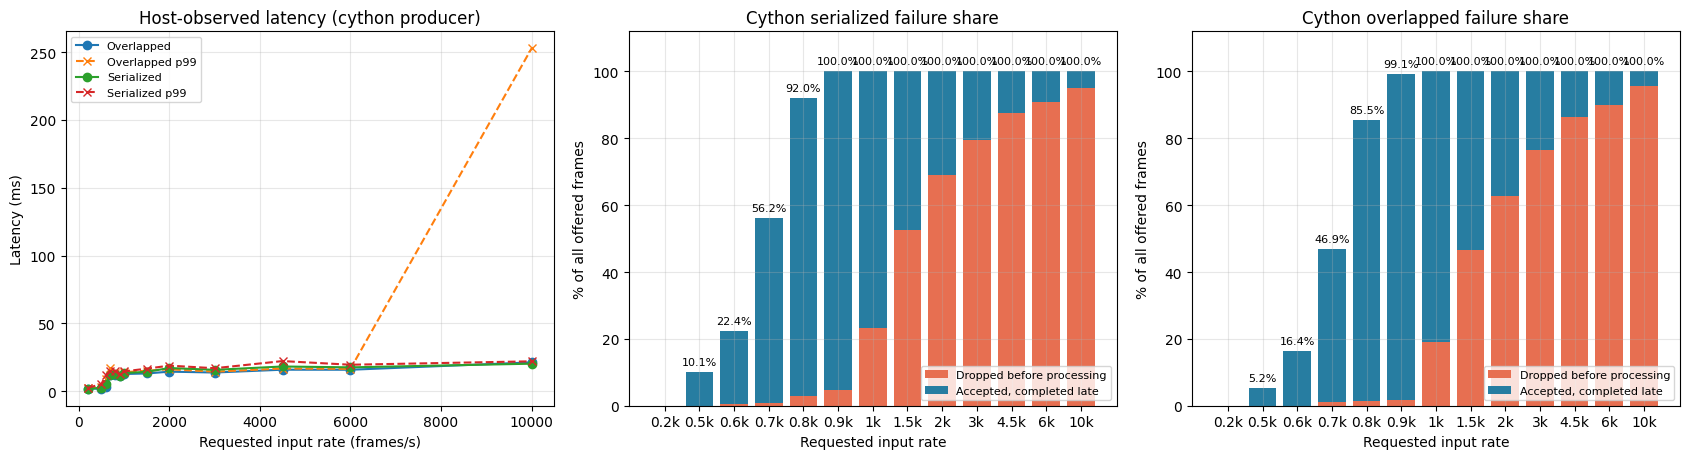

Saved: /content/realtime-beamforming-lab/results/exercise5-streaming-summary.json
Saved: /content/realtime-beamforming-lab/results/exercise5-streaming-power-maps.npz
Saved: /content/realtime-beamforming-lab/results/exercise5-streaming-latency.png


In [78]:
import matplotlib.pyplot as plt
import pandas as pd

summary_columns = [
    "producer_kind", "mode", "requested_rate_hz", "actual_producer_rate_hz", "offered_frames",
    "accepted_frames", "dropped_frames", "deadline_misses", "max_waiting_queue_depth",
    "latency_p50_ms", "latency_p95_ms", "latency_p99_ms", "latency_max_ms",
    "producer_lateness_p95_ms", "h2d_event_p50_ms",
    "gpu_beamform_power_p50_ms", "image_relative_rmse",
]
summary_rows = [{key: result.get(key) for key in summary_columns} for result in trial_results]
summary = pd.DataFrame(summary_rows)
summary["dropped_pct_offered"] = 100 * summary["dropped_frames"] / summary["offered_frames"]
summary["late_accepted_pct_offered"] = 100 * summary["deadline_misses"] / summary["offered_frames"]
summary["on_time_pct_offered"] = 100 - summary["dropped_pct_offered"] - summary["late_accepted_pct_offered"]
display(summary)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.7))
for _mode, _group in summary.groupby("mode"):
    _group = _group.sort_values("requested_rate_hz")
    _label = _mode.capitalize()
    axes[0].plot(_group["requested_rate_hz"], _group["latency_p95_ms"], marker="o", label=_label)
    axes[0].plot(_group["requested_rate_hz"], _group["latency_p99_ms"], marker="x", linestyle="--", label=f"{_label} p99")
axes[0].set(title=f"Host-observed latency ({MAIN_PRODUCER_KIND} producer)", xlabel="Requested input rate (frames/s)", ylabel="Latency (ms)")
axes[0].legend(fontsize=8)

_failure_colors = {"dropped": "#e76f51", "late": "#277da1"}
for _axis, _mode in zip(axes[1:], ("serialized", "overlapped")):
    _group = summary[summary["mode"] == _mode].sort_values("requested_rate_hz")
    _x = np.arange(len(_group))
    _dropped = _group["dropped_pct_offered"].to_numpy()
    _late = _group["late_accepted_pct_offered"].to_numpy()
    _axis.bar(_x, _dropped, color=_failure_colors["dropped"], label="Dropped before processing")
    _axis.bar(_x, _late, bottom=_dropped, color=_failure_colors["late"], label="Accepted, completed late")
    _axis.set_xticks(_x, [f"{rate / 1000:g}k" for rate in _group["requested_rate_hz"]])
    _axis.set(ylim=(0, 112), title=f"Cython {_mode} failure share", xlabel="Requested input rate", ylabel="% of all offered frames")
    for _position, _total in zip(_x, _dropped + _late):
        if _total > 0:
            _axis.text(_position, _total + 1.5, f"{_total:.1f}%", ha="center", va="bottom", fontsize=8)
    _axis.legend(fontsize=8, loc="lower right")
for _axis in axes:
    _axis.grid(True, alpha=0.3)
fig.tight_layout()
latency_plot_path = RESULTS_DIR / "exercise5-streaming-latency.png"
fig.savefig(latency_plot_path, dpi=180, bbox_inches="tight")
plt.show()

serializable_results = []
power_maps = {}
for _index, _result in enumerate(trial_results):
    _serializable = {key: value for key, value in _result.items() if key not in {"power_map", "normalized_map"}}
    serializable_results.append(_serializable)
    if _result["normalized_map"] is not None:
        _key = f"{_result['mode']}_{_result['requested_rate_hz']}Hz"
        power_maps[_key] = _result["normalized_map"].astype(np.float32)

json_path = RESULTS_DIR / "exercise5-streaming-summary.json"
json_path.write_text(json.dumps({
    "runtime": runtime_metadata,
    "dataset": workload.data_provenance,
    "configuration": {
        "cycles_per_trial": CYCLES_PER_TRIAL,
        "producer_kind": MAIN_PRODUCER_KIND,
        "recorded_frame_count": frame_count,
        "replayed_frames_per_trial": replay_frames,
        "nominal_recorded_prf_hz": REPLAYED_PRF_HZ,
        "requested_rates_hz": list(INPUT_RATES_HZ),
        "queue_capacity": QUEUE_CAPACITY,
        "drop_policy": "drop newest when the waiting queue is full",
        "deadline": "scheduled arrival plus one requested input period",
        "nvtx_available": NVTX_AVAILABLE,
    },
    "results": serializable_results,
}, indent=2))
npz_path = RESULTS_DIR / "exercise5-streaming-power-maps.npz"
np.savez_compressed(npz_path, **power_maps)
print("Saved:", json_path)
print("Saved:", npz_path)
print("Saved:", latency_plot_path)


## The primary comparison uses Cython scheduling

The main sweep compares serialized execution with the historical two-slot path across the 13 rates above. The Cython producer waits against absolute monotonic deadlines outside the GIL. The 10 kHz run accepted 411/8,192 serialized frames and 354/8,192 overlapped frames; every accepted frame was late against the 0.100 ms deadline. Median GPU beamform-plus-power time was 1.56 ms and 1.48 ms respectively.

The overlapped 10 kHz trial also had unusually high producer lateness (p95 217 ms; achieved rate 9,052/s), so its exact count is a one-run observation. Both paths show the same capacity gap: GPU work takes far longer than the input period.

### Selected timing rows from the Cython main sweep

The full per-rate table and plots above are the primary result. These rows show the low-load baseline and two saturated loads. Host latency runs from actual arrival through completion; GPU and H2D columns are CUDA event medians over accepted frames.

| Mode | Rate (Hz) | Accepted / offered | Dropped | Late | p95 host latency (ms) | H2D median (ms) | GPU median (ms) |
|---|---:|---:|---:|---:|---:|---:|---:|
| Serialized | 200 | 8,192 / 8,192 | 0 | 0 | 1.825 | 0.054 | 1.133 |
| Overlapped | 200 | 8,192 / 8,192 | 0 | 0 | 1.846 | 0.057 | 1.109 |
| Serialized | 6,000 | 750 / 8,192 | 7,442 | 750 | 17.571 | 0.061 | 1.423 |
| Overlapped | 6,000 | 831 / 8,192 | 7,361 | 831 | 15.805 | 0.060 | 1.315 |
| Serialized | 10,000 | 411 / 8,192 | 7,781 | 411 | 20.272 | 0.071 | 1.557 |
| Overlapped | 10,000 | 354 / 8,192 | 7,838 | 354 | 21.247 | 0.079 | 1.481 |

At 10 kHz, H2D is roughly 0.07–0.08 ms while GPU beamform-plus-power is 1.48–1.56 ms. Copy optimization may help, but the measured GPU work is the larger per-frame cost. The 10 kHz sample counts are small and the overlapped producer-lateness outlier is called out above.


## Follow-up: batch beamforming at 10 kHz

This follow-up varies `B`, the number of acquisitions passed on Mach's frame axis per call. Offline resident-input runs check image agreement and kernel scaling; scheduled runs measure throughput, queueing, deadlines, and output age. `B=1` is a fresh control against the main sweep.

A batch of `B` arrivals represents `B / rate` seconds. We therefore report both a batch deadline scaled to that span and the stricter one-period deadline for every frame, plus acquisition-to-output age. The scheduler uses two batch slots and zero-pads a partial final batch; only real arrivals count in results.

In [ ]:
from queue import Empty, Queue
from threading import Event, Thread
import time

from beamforming_lab.streaming import (
    BatchStreamSlot,
    enqueue_h2d_copy,
    make_batch_stream_slot,
    produce_cython_arrivals,
)


def run_batched_trial(
    batch_size: int,
    input_rate_hz: int = 10_000,
    queue_capacity: int = QUEUE_CAPACITY,
    mode: str = "overlapped",
) -> dict:
    if mode not in {"overlapped", "synchronous_default", "async", "async_explicit_stream"}:
        raise ValueError("unsupported submission mode")
    if batch_size < 1 or batch_size > frame_count:
        raise ValueError("batch_size must be between 1 and the recorded frame count")
    if input_rate_hz <= 0:
        raise ValueError("input_rate_hz must be positive")
    if queue_capacity < 1:
        raise ValueError("queue_capacity must be positive")

    period_ns = int(round(1e9 / input_rate_hz))
    max_fill_wait_ns = batch_size * period_ns
    offered_count = replay_frames
    # One compute stream serializes accumulation into the shared power map.
    # The default-stream modes use the NULL stream; other paths use a non-blocking stream.
    if mode in {"synchronous_default", "async"}:
        compute_stream = cp.cuda.Stream.null
    else:
        compute_stream = cp.cuda.Stream(non_blocking=True)
    slots = [
        make_batch_stream_slot(cp, batch_size, frame_shape, frame_bytes, compute_stream)
        for _ in range(2)
    ]
    power_accumulator = cp.zeros(len(workload.scan_coords_m), dtype=cp.float32)
    cp.cuda.Device().synchronize()
    work_queue = Queue(maxsize=queue_capacity)
    producer_done = Event()
    arrivals, drops, producer_errors = [], [], []
    max_queue_depth = [0]
    completed, batch_records = [], []
    max_queue_depth_seen = 0
    trial_start_ns = time.perf_counter_ns()

    def produce():
        try:
            max_queue_depth[0] = produce_cython_arrivals(
                work_queue,
                arrivals,
                drops,
                offered_count,
                frame_count,
                trial_start_ns,
                period_ns,
            )
        except BaseException as exc:
            producer_errors.append(exc)
        finally:
            producer_done.set()

    def submit(slot: BatchStreamSlot, jobs: list[dict]):
        stage_start_ns = time.perf_counter_ns()
        for index, job in enumerate(jobs):
            np.copyto(slot.host[:, :, index], channel_data[:, :, job["frame_index"]])
        if len(jobs) < batch_size:
            slot.host[:, :, len(jobs):] = 0
        slot.stage_start_ns = stage_start_ns
        slot.host_stage_ms = (time.perf_counter_ns() - stage_start_ns) / 1e6
        slot.jobs = jobs
        slot.batch_fill_ms = (jobs[-1]["arrived_ns"] - jobs[0]["arrived_ns"]) / 1e6
        slot.batch_span_slots = jobs[-1]["sequence"] - jobs[0]["sequence"] + 1

        enqueue_h2d_copy(
            cp,
            slot.host,
            slot.device,
            frame_bytes * batch_size,
            slot.copy_stream,
            slot.copy_start,
            slot.copy_done,
        )

        slot.compute_stream.wait_event(slot.copy_done)
        with slot.compute_stream:
            slot.compute_start.record(slot.compute_stream)
            beamform_kwargs = {
                "channel_data": slot.device,
                "rx_coords_m": geometry.rx_coords_m,
                "scan_coords_m": geometry.scan_coords_m,
                "tx_wave_arrivals_s": geometry.tx_wave_arrivals_s,
                "f_number": float(workload.params["fnumber"]),
                "rx_start_s": float(workload.params["t0"]),
                "sampling_freq_hz": float(workload.params["fs"]),
                "sound_speed_m_s": float(workload.params["c"]),
                "modulation_freq_hz": float(workload.params["fc"]),
                "tukey_alpha": 0.0,
            }
            if mode in {"async", "async_explicit_stream"}:
                beamform_kwargs["synchronize"] = False
            if mode == "async_explicit_stream":
                beamform_kwargs["stream"] = slot.compute_stream
            image = beamform(**beamform_kwargs)
            batch_power = cp.sum(cp.abs(image) ** 2, axis=-1)
            cp.add(power_accumulator, batch_power, out=power_accumulator)
            # Retain asynchronous outputs until the completion event has fired.
            slot.pending_refs = (image, batch_power)
            slot.compute_done.record(slot.compute_stream)

    def finish(slot: BatchStreamSlot):
        completed_ns = time.perf_counter_ns()
        jobs = slot.jobs
        span_slots = slot.batch_span_slots
        deadline_ns = jobs[-1]["scheduled_ns"] + span_slots * period_ns
        batch_late = completed_ns > deadline_ns
        batch_records.append({
            "batch_size": len(jobs),
            "represented_slots": span_slots,
            "batch_fill_ms": slot.batch_fill_ms,
            "queue_wait_ms": (slot.stage_start_ns - jobs[0]["arrived_ns"]) / 1e6,
            "host_stage_ms": slot.host_stage_ms,
            "dispatch_to_done_ms": (completed_ns - slot.stage_start_ns) / 1e6,
            "ready_to_done_ms": (completed_ns - jobs[-1]["arrived_ns"]) / 1e6,
            "batch_deadline_ms": span_slots * period_ns / 1e6,
            "batch_late": batch_late,
            "h2d_ms": float(cp.cuda.get_elapsed_time(slot.copy_start, slot.copy_done)),
            "gpu_ms": float(cp.cuda.get_elapsed_time(slot.compute_start, slot.compute_done)),
        })
        for job in jobs:
            completed.append({
                **job,
                "completed_ns": completed_ns,
                "host_latency_ms": (completed_ns - job["arrived_ns"]) / 1e6,
                "scheduled_age_ms": (completed_ns - job["scheduled_ns"]) / 1e6,
                "queue_wait_ms": (slot.stage_start_ns - job["arrived_ns"]) / 1e6,
                "batch_deadline_miss": batch_late,
                "strict_frame_deadline_miss": completed_ns > job["scheduled_ns"] + period_ns,
            })
        slot.jobs = None
        slot.pending_refs = ()

    _nvtx_pushed = False
    if NVTX_AVAILABLE:
        RangePush(f"exercise5/cython/{mode}/{input_rate_hz}Hz/batch{batch_size}/queue{queue_capacity}")
        _nvtx_pushed = True
    producer = Thread(target=produce, name=f"exercise5-cython-batch{batch_size}-producer", daemon=True)
    pending: list[dict] = []
    producer.start()
    try:
        while True:
            progressed = False
            for slot in slots:
                if slot.jobs is not None and slot.compute_done.done:
                    finish(slot)
                    progressed = True

            max_queue_depth_seen = max(max_queue_depth_seen, max_queue_depth[0], work_queue.qsize())
            free_slot = next((slot for slot in slots if slot.jobs is None), None)
            if free_slot is not None:
                while len(pending) < batch_size:
                    try:
                        pending.append(work_queue.get_nowait())
                        progressed = True
                    except Empty:
                        break
                flush_partial = bool(pending) and (
                    producer_done.is_set() and work_queue.empty()
                    or time.perf_counter_ns() - pending[0]["arrived_ns"] >= max_fill_wait_ns
                )
                if len(pending) == batch_size or flush_partial:
                    submit(free_slot, pending.copy())
                    pending.clear()
                    progressed = True

            if producer_done.is_set() and work_queue.empty() and not pending and all(slot.jobs is None for slot in slots):
                break
            if not progressed:
                time.sleep(POLL_INTERVAL_S)
    finally:
        producer.join()
        for slot in slots:
            if slot.jobs is not None:
                slot.compute_done.synchronize()
                finish(slot)
        if _nvtx_pushed:
            RangePop()

    if producer_errors:
        raise RuntimeError("Cython batch producer failed") from producer_errors[0]
    cp.cuda.Device().synchronize()
    power_map = cp.asnumpy(power_accumulator).reshape(len(workload.x_m), len(workload.z_m))
    trial_end_ns = time.perf_counter_ns()

    accepted = len(completed)
    batch_late_frames = sum(r["batch_deadline_miss"] for r in completed)
    strict_late_frames = sum(r["strict_frame_deadline_miss"] for r in completed)
    producer_lateness_ms = np.asarray([(r["arrived_ns"] - r["scheduled_ns"]) / 1e6 for r in arrivals])
    host_latency_ms = np.asarray([r["host_latency_ms"] for r in completed])
    scheduled_age_ms = np.asarray([r["scheduled_age_ms"] for r in completed])
    batch_gpu_ms = np.asarray([r["gpu_ms"] for r in batch_records])
    batch_h2d_ms = np.asarray([r["h2d_ms"] for r in batch_records])
    batch_fill_ms = np.asarray([r["batch_fill_ms"] for r in batch_records])
    batch_stage_ms = np.asarray([r["host_stage_ms"] for r in batch_records])
    batch_wall_ms = np.asarray([r["dispatch_to_done_ms"] for r in batch_records])
    batch_ready_ms = np.asarray([r["ready_to_done_ms"] for r in batch_records])
    actual_rate_hz = (
        (len(arrivals) - 1) * 1e9 / (arrivals[-1]["arrived_ns"] - arrivals[0]["arrived_ns"])
        if len(arrivals) > 1 and arrivals[-1]["arrived_ns"] > arrivals[0]["arrived_ns"] else 0.0
    )
    image_relative_rmse = None
    if accepted == offered_count and not drops:
        normalized_map = power_map / CYCLES_PER_TRIAL
        image_relative_rmse = float(
            np.sqrt(np.mean((normalized_map - reference) ** 2))
            / max(np.sqrt(np.mean(reference ** 2)), np.finfo(float).eps)
        )

    return {
        "producer_kind": "cython",
        "mode": mode,
        "batch_size_target": batch_size,
        "queue_capacity_frames": queue_capacity,
        "requested_rate_hz": input_rate_hz,
        "actual_producer_rate_hz": float(actual_rate_hz),
        "offered_frames": offered_count,
        "accepted_frames": accepted,
        "dropped_frames": len(drops),
        "batch_deadline_miss_frames": int(batch_late_frames),
        "strict_frame_deadline_miss_frames": int(strict_late_frames),
        "batch_deadline_failure_share_pct": 100 * (len(drops) + batch_late_frames) / offered_count,
        "strict_frame_failure_share_pct": 100 * (len(drops) + strict_late_frames) / offered_count,
        "max_waiting_queue_depth": int(max_queue_depth_seen),
        "trial_wall_s": (trial_end_ns - trial_start_ns) / 1e9,
        "completed_frames_per_s": accepted / ((trial_end_ns - trial_start_ns) / 1e9),
        "latency_p50_ms": float(np.percentile(host_latency_ms, 50)) if accepted else None,
        "latency_p95_ms": float(np.percentile(host_latency_ms, 95)) if accepted else None,
        "scheduled_age_p95_ms": float(np.percentile(scheduled_age_ms, 95)) if accepted else None,
        "producer_lateness_p95_ms": float(np.percentile(producer_lateness_ms, 95)) if len(arrivals) else None,
        "batch_size_mean": float(np.mean([b["batch_size"] for b in batch_records])) if batch_records else None,
        "batch_fill_p50_ms": float(np.percentile(batch_fill_ms, 50)) if len(batch_fill_ms) else None,
        "host_stage_p50_ms_per_batch": float(np.percentile(batch_stage_ms, 50)) if len(batch_stage_ms) else None,
        "batch_wall_p50_ms": float(np.percentile(batch_wall_ms, 50)) if len(batch_wall_ms) else None,
        "ready_to_done_p50_ms": float(np.percentile(batch_ready_ms, 50)) if len(batch_ready_ms) else None,
        "batch_deadline_p50_ms": float(np.percentile([b["batch_deadline_ms"] for b in batch_records], 50)) if batch_records else None,
        "h2d_event_p50_ms_per_batch": float(np.percentile(batch_h2d_ms, 50)) if len(batch_h2d_ms) else None,
        "gpu_event_p50_ms_per_batch": float(np.percentile(batch_gpu_ms, 50)) if len(batch_gpu_ms) else None,
        "image_relative_rmse": image_relative_rmse,
        "power_map": power_map,
        "batch_records": batch_records,
        "frame_records": completed,
        "drops": drops,
    }


Offline full-ensemble batch check (resident input; no arrival queue):
B=1: GPU=29.415 ms, wall=38.839 ms, 824 frames/s, RMSE=0.00e+00
B=2: GPU=20.506 ms, wall=26.616 ms, 1202 frames/s, RMSE=1.18e-07
B=4: GPU=13.609 ms, wall=18.062 ms, 1772 frames/s, RMSE=1.16e-07
B=8: GPU=5.625 ms, wall=8.903 ms, 3594 frames/s, RMSE=1.14e-07
B=16: GPU=3.027 ms, wall=5.841 ms, 5479 frames/s, RMSE=1.11e-07

Cython overlapped replay at 10,000 Hz (8,192 offered frames each):
B=1: accepted=503, dropped=7,689, batch-late=503, failure=100.0%, throughput=607 frames/s, p95 age=17.32 ms
B=2: accepted=708, dropped=7,484, batch-late=708, failure=100.0%, throughput=856 frames/s, p95 age=12.81 ms
B=4: accepted=880, dropped=7,312, batch-late=880, failure=100.0%, throughput=1063 frames/s, p95 age=13.48 ms
B=8: accepted=1,208, dropped=6,984, batch-late=1,208, failure=100.0%, throughput=1463 frames/s, p95 age=12.59 ms
B=16: accepted=952, dropped=7,240, batch-late=952, failure=100.0%, throughput=1151 frames/s, p95 age=16

B,GPU ms / ensemble,Wall ms,Frames/s,RMSE vs B=1
1,29.415,38.839,824,0.00e+00
2,20.506,26.616,1202,1.18e-07
4,13.609,18.062,1772,1.16e-07
8,5.625,8.903,3594,1.14e-07
16,3.027,5.841,5479,1.11e-07


B,Accepted,Dropped,Batch-late,Failure %,Accepted frames/s,p95 age (ms),GPU ms/batch,Budget (ms)
1,503,7689,503,100.0,607,17.32,1.248,0.10
2,708,7484,708,100.0,856,12.81,1.443,0.20
4,880,7312,880,100.0,1063,13.48,2.060,0.40
8,1208,6984,1208,100.0,1463,12.59,1.812,0.80
16,952,7240,952,100.0,1151,16.02,1.782,1.60


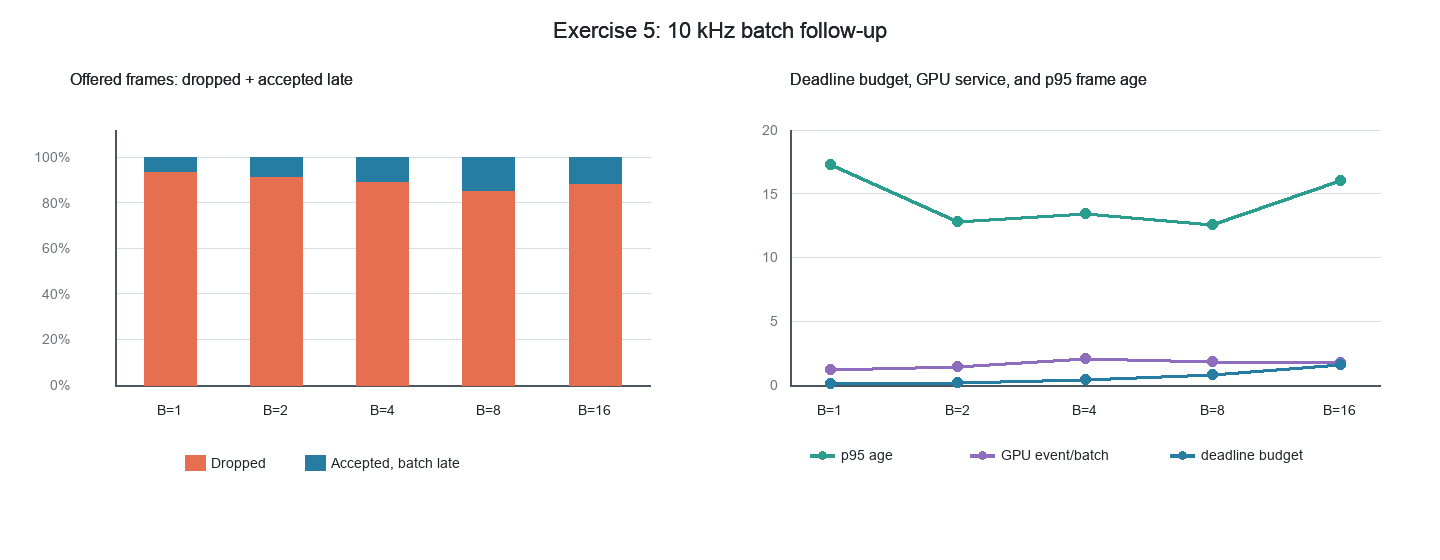

In [80]:
BATCH_SIZES = (1, 2, 4, 8, 16)
BATCH_TEST_RATE_HZ = 10_000
BATCH_REPEATS = 3

# First check batch-axis image agreement and resident-input kernel scaling.
# The first call for each size is a warmup; timings below are medians of repeats.
offline_batch_rows = []
for _batch_size in BATCH_SIZES:
    run_ensemble(workload, geometry, batch_size=_batch_size)
    _offline_runs = [run_ensemble(workload, geometry, batch_size=_batch_size) for _ in range(BATCH_REPEATS)]
    _offline_image = _offline_runs[-1]["power_doppler"]
    _offline_diff = _offline_image - reference
    offline_batch_rows.append({
        "batch_size": _batch_size,
        "beamform_device_ms": float(np.median([r["beamform_device_ms"] for r in _offline_runs])),
        "beamform_host_call_ms": float(np.median([r["beamform_host_call_ms"] for r in _offline_runs])),
        "one_time_upload_ms": float(np.median([r["input_upload_ms"] for r in _offline_runs])),
        "ensemble_wall_ms": float(np.median([r["run_wall_ms"] for r in _offline_runs])),
        "frames_per_second_wall": frame_count * 1_000 / float(np.median([r["run_wall_ms"] for r in _offline_runs])),
        "image_relative_rmse_vs_B1": float(
            np.sqrt(np.mean(_offline_diff ** 2))
            / max(np.sqrt(np.mean(reference ** 2)), np.finfo(float).eps)
        ),
    })
offline_batch_summary = pd.DataFrame(offline_batch_rows)
print("Offline full-ensemble batch check (resident input; no arrival queue):")
display(offline_batch_summary)

# Then test scheduled arrivals and the batch-cadence deadline at 10 kHz.
batch_trial_results = []
for _batch_size in BATCH_SIZES:
    print(f"Running Cython overlapped replay at {BATCH_TEST_RATE_HZ:,} Hz, batch={_batch_size} ...")
    _result = run_batched_trial(_batch_size, input_rate_hz=BATCH_TEST_RATE_HZ)
    batch_trial_results.append(_result)
    print(
        f"  accepted={_result['accepted_frames']:,}, dropped={_result['dropped_frames']:,}, "
        f"batch-late={_result['batch_deadline_miss_frames']:,}, "
        f"batch failure={_result['batch_deadline_failure_share_pct']:.1f}%, "
        f"completed={_result['completed_frames_per_s']:.0f} frames/s, "
        f"p95 age={_result['scheduled_age_p95_ms']:.3f} ms"
    )

batch_summary_rows = []
for _result in batch_trial_results:
    batch_summary_rows.append({key: value for key, value in _result.items()
                               if key not in {"power_map", "batch_records", "frame_records", "drops"}})
batch_summary = pd.DataFrame(batch_summary_rows)
batch_display_columns = [
    "batch_size_target", "accepted_frames", "dropped_frames",
    "batch_deadline_miss_frames", "batch_deadline_failure_share_pct",
    "strict_frame_failure_share_pct", "completed_frames_per_s",
    "scheduled_age_p95_ms", "gpu_event_p50_ms_per_batch", "batch_deadline_p50_ms",
]
batch_display = batch_summary[batch_display_columns].rename(columns={
    "batch_size_target": "B", "accepted_frames": "Accepted", "dropped_frames": "Dropped",
    "batch_deadline_miss_frames": "Batch-late", "batch_deadline_failure_share_pct": "Batch failure (%)",
    "strict_frame_failure_share_pct": "Strict failure (%)", "completed_frames_per_s": "Accepted frames/s",
    "scheduled_age_p95_ms": "p95 age (ms)", "gpu_event_p50_ms_per_batch": "GPU ms/batch",
    "batch_deadline_p50_ms": "Batch budget (ms)",
})
display(batch_display)

offered = batch_summary["offered_frames"].to_numpy()
dropped_pct = 100 * batch_summary["dropped_frames"].to_numpy() / offered
late_pct = 100 * batch_summary["batch_deadline_miss_frames"].to_numpy() / offered
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
_x = np.arange(len(BATCH_SIZES))
axes[0].bar(_x, dropped_pct, color="#e76f51", label="Dropped")
axes[0].bar(_x, late_pct, bottom=dropped_pct, color="#277da1", label="Accepted, batch late")
axes[0].set_xticks(_x, [str(b) for b in BATCH_SIZES])
axes[0].set(xlabel="Acquisitions per beamform call", ylabel="% of offered frames",
            title="10 kHz batch-aware failure share", ylim=(0, 112))
axes[0].legend()
axes[0].grid(True, axis="y", alpha=0.3)
axes[1].plot(BATCH_SIZES, batch_summary["scheduled_age_p95_ms"], marker="o", label="p95 acquisition-to-output age")
axes[1].plot(BATCH_SIZES, batch_summary["batch_deadline_p50_ms"], marker="s", label="median batch deadline budget")
axes[1].plot(BATCH_SIZES, batch_summary["gpu_event_p50_ms_per_batch"], marker="^", label="GPU event median per batch")
axes[1].set(xlabel="Target acquisitions per beamform call", ylabel="Time (ms)",
            title="Batch cadence and frame age")
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=8)
fig.tight_layout()
batch_plot_path = RESULTS_DIR / "exercise5-batching-10khz.png"
fig.savefig(batch_plot_path, dpi=180, bbox_inches="tight")
plt.show()

batch_json_path = RESULTS_DIR / "exercise5-batching-10khz.json"
batch_json_path.write_text(json.dumps({
    "runtime": runtime_metadata,
    "dataset": workload.data_provenance,
    "configuration": {
        "requested_rate_hz": BATCH_TEST_RATE_HZ,
        "batch_sizes": list(BATCH_SIZES),
        "producer_kind": "cython",
        "pipeline_mode": "overlapped",
        "queue_capacity_frames": QUEUE_CAPACITY,
        "max_fill_wait_periods": 1,
        "batch_deadline": "scheduled last represented slot plus represented_slots / requested_rate",
        "strict_per_frame_deadline": "scheduled arrival plus one input period",
        "offline_batch_repeats": BATCH_REPEATS,
    },
    "offline_batch_results": offline_batch_rows,
    "streaming_results": [
        {key: value for key, value in result.items()
         if key not in {"power_map", "batch_records", "frame_records", "drops"}}
        for result in batch_trial_results
    ],
}, indent=2))
complete_batch_maps = {
    f"batch_{r['batch_size_target']}": r["power_map"].astype(np.float32)
    for r in batch_trial_results if r["image_relative_rmse"] is not None
}
print("Saved:", batch_json_path)
if complete_batch_maps:
    batch_npz_path = RESULTS_DIR / "exercise5-batching-10khz-power-maps.npz"
    np.savez_compressed(batch_npz_path, **complete_batch_maps)
    print("Saved:", batch_npz_path)
else:
    print("No complete streaming power-map archive: no trial accepted the full replay.")
print("Saved:", batch_plot_path)


## Reading the batch results

With all 32 inputs resident, offline throughput rose from about 824 acquisitions/s at `B=1` to 5,479/s at `B=16`; beamform time fell from 29.4 ms to 3.03 ms. Power-map relative RMSE stayed at or below `1.18e-7`.

In the scheduled 10 kHz run, `B=8` was fastest at about 1,463 completed acquisitions/s (2.4× the fresh `B=1` control). Every offered frame was dropped or late at every batch size. At `B=8`, the batch deadline was 0.8 ms while median GPU event time was 1.81 ms. The p95 acquisition-to-output age was 12.59 ms; `B=16` fell to about 1,151/s and raised p95 age to 16.02 ms.

The 8,192-frame queue follow-up later completed the full map (RMSE `3.70e-6`), but every frame missed its batch deadline. Scheduled `B=32` remained partial; its offline map RMSE was `1.11e-7`.

## Follow-up: queue capacity and a full-ensemble batch

At 10 kHz, this test holds `B=8` and raises the waiting queue from 8 to 8,192 frames. It then tests scheduled `B=32` with the original eight-frame queue. The queue drops the newest arrival when full. This separates the effect of buffering from the effect of more work per beamform call.

Queue cap 8: accepted=1,112, dropped=7,080, batch-late=1,112, failure=100.0%, completed=1342 frames/s, p95 age=14.349 ms
Queue cap 64: accepted=1,160, dropped=7,032, batch-late=1,160, failure=100.0%, completed=1346 frames/s, p95 age=58.817 ms
Queue cap 512: accepted=1,624, dropped=6,568, batch-late=1,624, failure=100.0%, completed=1415 frames/s, p95 age=387.961 ms
Queue cap 2,048: accepted=3,208, dropped=4,984, batch-late=3,208, failure=100.0%, completed=1560 frames/s, p95 age=1316.302 ms
Queue cap 8,192: accepted=8,192, dropped=0, batch-late=8,192, failure=100.0%, completed=1608 frames/s, p95 age=4038.307 ms


Queue cap,Accepted,Dropped,Batch-late,Failure (%),Frames/s,p95 age (ms)
8,"1,112","7,080","1,112",100.0,"1,342",14.3
64,"1,160","7,032","1,160",100.0,"1,346",58.8
512,"1,624","6,568","1,624",100.0,"1,415",388.0
"2,048","3,208","4,984","3,208",100.0,"1,560","1,316.3"
"8,192","8,192",0,"8,192",100.0,"1,608","4,038.3"


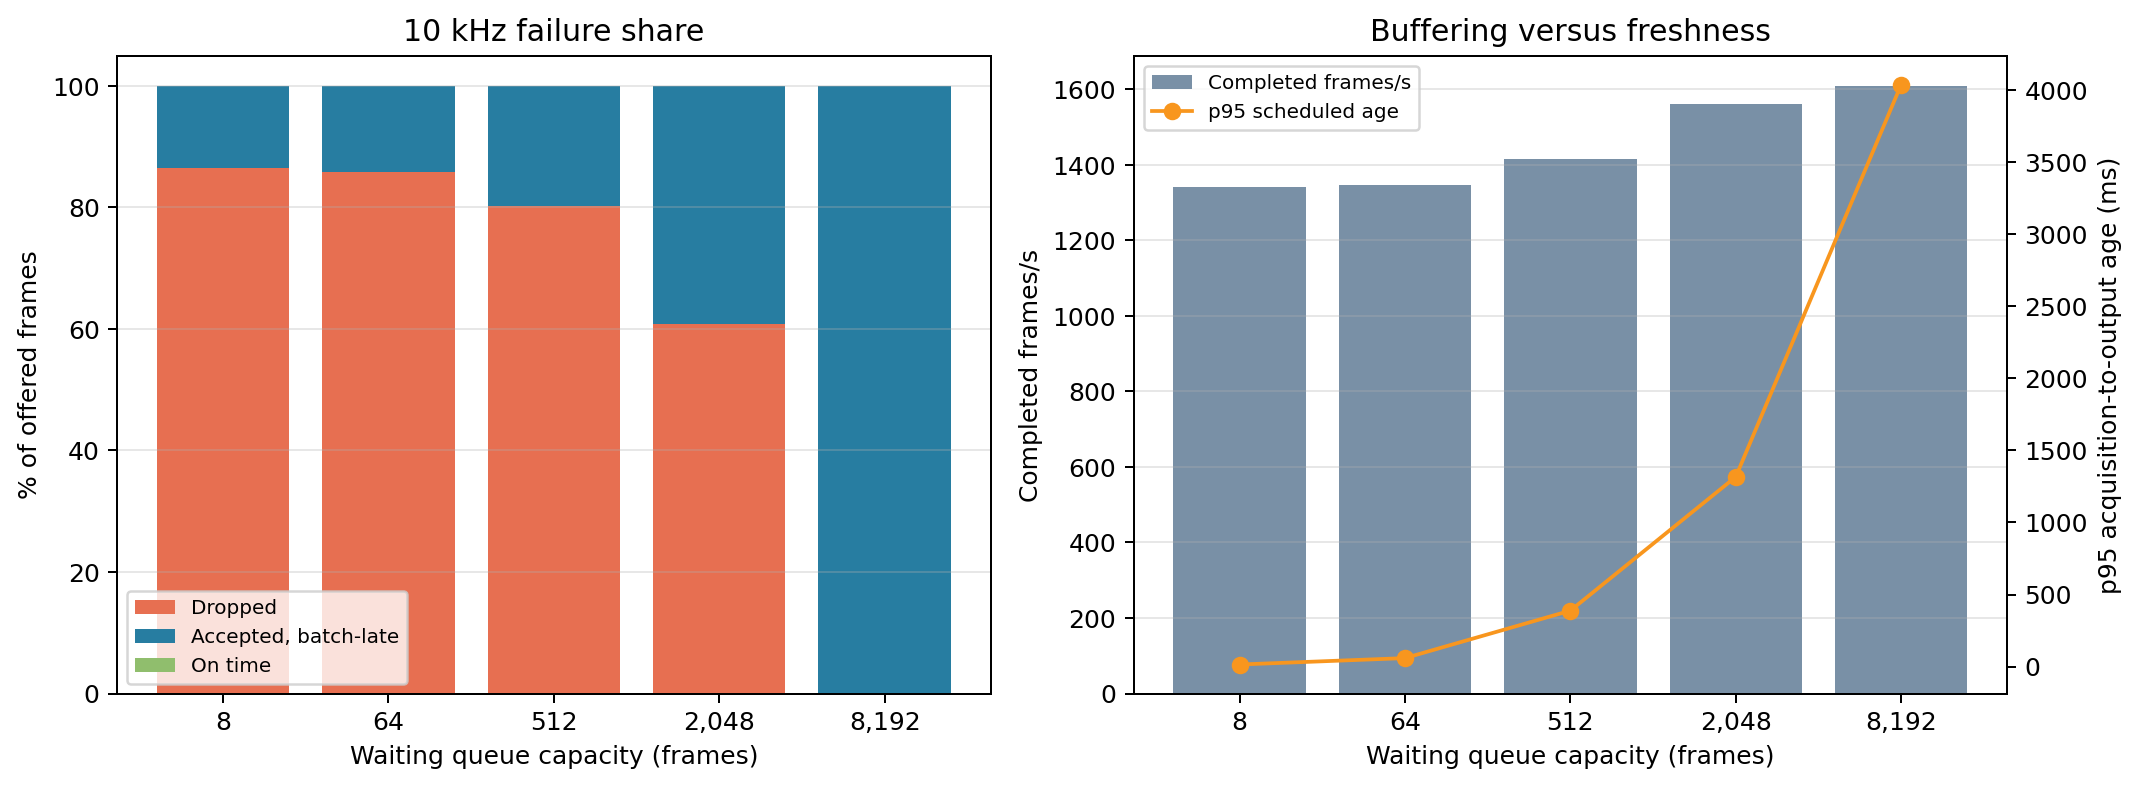


Offline B=32: 3681 frames/s, GPU event=4.487 ms, relative RMSE=1.114e-07.
Scheduled B=32 target, queue cap 8: accepted=648, dropped=7,544, failure=100.0%, throughput=773 frames/s, p95 age=37.355 ms, mean realized batch=8.31, GPU event p50=3.876 ms.

Saved results: results/exercise5-queue-depth-10khz.json, results/exercise5-queue-depth-10khz.png, and results/exercise5-queue-depth-10khz-power-maps.npz


In [81]:
QUEUE_DEPTH_RATE_HZ = 10_000
QUEUE_DEPTH_BATCH_SIZE = 8
QUEUE_CAPACITIES = (8, 64, 512, 2_048, replay_frames)
LARGER_BATCH_SIZE = frame_count

queue_depth_results = []
for _capacity in QUEUE_CAPACITIES:
    print(
        f"Running B={QUEUE_DEPTH_BATCH_SIZE} at {QUEUE_DEPTH_RATE_HZ:,} Hz "
        f"with queue capacity={_capacity:,} ..."
    )
    _result = run_batched_trial(
        QUEUE_DEPTH_BATCH_SIZE,
        input_rate_hz=QUEUE_DEPTH_RATE_HZ,
        queue_capacity=_capacity,
    )
    queue_depth_results.append(_result)
    print(
        f"  accepted={_result['accepted_frames']:,}, dropped={_result['dropped_frames']:,}, "
        f"batch-late={_result['batch_deadline_miss_frames']:,}, "
        f"failure={_result['batch_deadline_failure_share_pct']:.1f}%, "
        f"completed={_result['completed_frames_per_s']:.0f} frames/s, "
        f"p95 age={_result['scheduled_age_p95_ms']:.3f} ms"
    )

queue_depth_summary = pd.DataFrame([
    {key: value for key, value in result.items()
     if key not in {"power_map", "batch_records", "frame_records", "drops"}}
    for result in queue_depth_results
])
queue_depth_columns = [
    "queue_capacity_frames", "accepted_frames", "dropped_frames",
    "batch_deadline_miss_frames", "batch_deadline_failure_share_pct",
    "completed_frames_per_s", "scheduled_age_p95_ms",
    "max_waiting_queue_depth",
]
queue_depth_display = queue_depth_summary[queue_depth_columns].rename(columns={
    "queue_capacity_frames": "Queue capacity", "accepted_frames": "Accepted",
    "dropped_frames": "Dropped", "batch_deadline_miss_frames": "Batch-late",
    "batch_deadline_failure_share_pct": "Failure (%)",
    "completed_frames_per_s": "Frames/s", "scheduled_age_p95_ms": "p95 age (ms)",
    "max_waiting_queue_depth": "Max queue depth",
})
display(queue_depth_display)

offered = queue_depth_summary["offered_frames"].to_numpy()
dropped_pct = 100 * queue_depth_summary["dropped_frames"].to_numpy() / offered
late_pct = 100 * queue_depth_summary["batch_deadline_miss_frames"].to_numpy() / offered
on_time_pct = np.maximum(0, 100 - dropped_pct - late_pct)
_labels = [f"{value:,}" for value in QUEUE_CAPACITIES]
_x = np.arange(len(QUEUE_CAPACITIES))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(_x, dropped_pct, color="#e76f51", label="Dropped")
axes[0].bar(_x, late_pct, bottom=dropped_pct, color="#277da1", label="Accepted, batch-late")
axes[0].bar(_x, on_time_pct, bottom=dropped_pct + late_pct,
            color="#90be6d", label="On time")
axes[0].set_xticks(_x, _labels)
axes[0].set(xlabel="Waiting queue capacity (frames)", ylabel="% of offered frames",
            title="10 kHz failure share", ylim=(0, 105))
axes[0].legend(fontsize=8)
axes[0].grid(True, axis="y", alpha=0.3)
axes[1].bar(_x, queue_depth_summary["completed_frames_per_s"],
            color="#577590", alpha=0.8, label="Completed frames/s")
axes[1].set_xticks(_x, _labels)
axes[1].set(xlabel="Waiting queue capacity (frames)", ylabel="Completed frames/s",
            title="Buffering versus freshness")
_age_axis = axes[1].twinx()
_age_axis.plot(_x, queue_depth_summary["scheduled_age_p95_ms"],
               color="#f8961e", marker="o", label="p95 scheduled age")
_age_axis.set_ylabel("p95 acquisition-to-output age (ms)")
_axes_handles = axes[1].get_legend_handles_labels()
_age_handles = _age_axis.get_legend_handles_labels()
axes[1].legend(_axes_handles[0] + _age_handles[0],
               _axes_handles[1] + _age_handles[1], fontsize=8)
axes[1].grid(True, axis="y", alpha=0.3)
fig.tight_layout()
queue_depth_plot_path = RESULTS_DIR / "exercise5-queue-depth-10khz.png"
fig.savefig(queue_depth_plot_path, dpi=180, bbox_inches="tight")
plt.show()

# Check the largest practical batch against the B=1 reference, then replay it
# with the original eight-frame waiting queue to isolate the compute knob.
print(f"Checking the full {LARGER_BATCH_SIZE}-frame batch offline ...")
larger_batch_offline = run_ensemble(
    workload, geometry, batch_size=LARGER_BATCH_SIZE
)
_larger_diff = larger_batch_offline["power_doppler"] - reference
larger_batch_offline_summary = {
    "batch_size": LARGER_BATCH_SIZE,
    "beamform_device_ms": float(larger_batch_offline["beamform_device_ms"]),
    "beamform_host_call_ms": float(larger_batch_offline["beamform_host_call_ms"]),
    "ensemble_wall_ms": float(larger_batch_offline["run_wall_ms"]),
    "frames_per_second_wall": frame_count * 1_000 / float(larger_batch_offline["run_wall_ms"]),
    "image_relative_rmse_vs_B1": float(
        np.sqrt(np.mean(_larger_diff ** 2))
        / max(np.sqrt(np.mean(reference ** 2)), np.finfo(float).eps)
    ),
}
print("Running the scheduled full-ensemble batch at the original queue capacity ...")
larger_batch_result = run_batched_trial(
    LARGER_BATCH_SIZE,
    input_rate_hz=QUEUE_DEPTH_RATE_HZ,
    queue_capacity=QUEUE_CAPACITY,
)
print(
    f"  accepted={larger_batch_result['accepted_frames']:,}, "
    f"dropped={larger_batch_result['dropped_frames']:,}, "
    f"batch-late={larger_batch_result['batch_deadline_miss_frames']:,}, "
    f"failure={larger_batch_result['batch_deadline_failure_share_pct']:.1f}%, "
    f"completed={larger_batch_result['completed_frames_per_s']:.0f} frames/s, "
    f"p95 age={larger_batch_result['scheduled_age_p95_ms']:.3f} ms"
)

queue_depth_json_path = RESULTS_DIR / "exercise5-queue-depth-10khz.json"
queue_depth_json_path.write_text(json.dumps({
    "runtime": runtime_metadata,
    "dataset": workload.data_provenance,
    "configuration": {
        "requested_rate_hz": QUEUE_DEPTH_RATE_HZ,
        "queue_depth_batch_size": QUEUE_DEPTH_BATCH_SIZE,
        "queue_capacities_frames": list(QUEUE_CAPACITIES),
        "drop_policy": "drop newest when the waiting queue is full",
        "larger_batch_size": LARGER_BATCH_SIZE,
        "larger_batch_queue_capacity_frames": QUEUE_CAPACITY,
        "deadline": "scheduled last represented slot plus represented_slots / requested_rate",
    },
    "queue_depth_results": [
        {key: value for key, value in result.items()
         if key not in {"power_map", "batch_records", "frame_records", "drops"}}
        for result in queue_depth_results
    ],
    "larger_batch_offline": larger_batch_offline_summary,
    "larger_batch_streaming": {
        key: value for key, value in larger_batch_result.items()
        if key not in {"power_map", "batch_records", "frame_records", "drops"}
    },
}, indent=2))
_complete_maps = {
    f"queue_{r['queue_capacity_frames']}": r["power_map"].astype(np.float32)
    for r in queue_depth_results if r["image_relative_rmse"] is not None
}
if larger_batch_result["image_relative_rmse"] is not None:
    _complete_maps[f"batch_{LARGER_BATCH_SIZE}"] = larger_batch_result["power_map"].astype(np.float32)
if _complete_maps:
    queue_depth_npz_path = RESULTS_DIR / "exercise5-queue-depth-10khz-power-maps.npz"
    np.savez_compressed(queue_depth_npz_path, **_complete_maps)
    print("Saved complete-replay maps:", queue_depth_npz_path)
else:
    print("No complete-replay power maps were produced.")
print("Saved:", queue_depth_json_path)
print("Saved:", queue_depth_plot_path)
print("Full-ensemble batch offline check:", larger_batch_offline_summary)


## Queue-depth results and what remains

At `B=8` and 10 kHz, raising queue capacity from 8 to 8,192 changed the outcome from 7,080 drops to accepting all 8,192 frames. It did not improve deadline completion: all frames were late, p95 output age grew to 4.04 s, and throughput rose only from 1,342 to 1,608 frames/s. The full replay's power map had relative RMSE `3.70e-6`.

Scheduled `B=32` accepted 648 frames at queue capacity 8; the mean realized batch was 8.31, not 32. Its offline resident-input throughput was 3,681/s, below `B=16` at 5,479/s. Increasing target batch size alone did not close the service-rate gap.

### Two separate optimization directions

- **Run independent beamforms concurrently** only if a single beamform leaves useful GPU execution capacity available. The initial `B=16` attempt was not a valid concurrency test because it omitted Mach's stream and async arguments. The corrected `B=8` test below achieved brief overlap but only a 0.9% median gain.
- **Reduce idle gaps** by batching work and allowing host submission or H2D copies to proceed during GPU execution. Batching and async improved completed throughput, but the 10 kHz workload still missed every deadline.

A larger queue trades drops for stale output; it does not raise sustained service capacity.

## Nsight Systems profiling and interpretations

The scheduled rate sweep marks each mode/rate with NVTX. The final two-stream trace is [`artifacts/exercise5-b8-two-compute-streams.nsys-rep`](../artifacts/exercise5-b8-two-compute-streams.nsys-rep), with its timing data in [`results/exercise5-b8-two-compute-streams.json`](../results/exercise5-b8-two-compute-streams.json).

- At 200 Hz, both main paths completed all 8,192 frames on time. Deadline misses appeared at 500 Hz; drops first appeared at 600 Hz serialized and 700 Hz overlapped. By 1 kHz, no accepted frame completed within one input period.
- At 10 kHz, the period is 0.100 ms versus 1.48–1.56 ms for GPU beamform-plus-power. Most arrivals were dropped by the bounded queue; accepted arrivals were late. H2D was about 0.05–0.08 ms in selected rows, much shorter than GPU work.
- For the combined `B=8` run, async default reached 1,962 completed acquisitions/s versus 1,646 for its paired synchronous control (+19.2%). Every offered frame still dropped or completed late.
- The corrected two-stream test ran four `B=8` calls over 32 resident inputs. Median throughput was 2,840/s vs 2,815/s on one stream (+0.9%); Nsight showed only two overlap windows, 26.7 and 29.1 μs, between kernels about 1.54 ms each. No Nsight Compute counters were collected for this run.

An isolated `B=8` Nsight Compute beamform profile reported 42.56% active warps and 39.91% SM throughput. These are single-kernel profile metrics, not measures of the two-stream run or total pipeline utilization. Nsight captures are diagnostic; their measured throughput varied substantially under instrumentation. The scheduled replay and resident-input stream test answer different questions.

## Mach’s call path and the overlap limit

The consumer stages each acquisition from pinned host memory into a CuPy slot, calls `mach.kernel.beamform()`, then accumulates power on the GPU. Mach's v0.2.1 Python wrapper calls a native CUDA function that launches on the NULL/default stream and calls `cudaDeviceSynchronize()`. This blocks the host until device work completes, preventing the consumer from queueing the next copy during that wait. ([Mach wrapper](https://github.com/Forest-Neurotech/mach/blob/v0.2.1/src/mach/kernel.py#L274), [kernel launch and wait](https://github.com/Forest-Neurotech/mach/blob/v0.2.1/src/mach/kernel.cu#L884), [CUDA synchronization](https://docs.nvidia.com/cuda/cuda-programming-guide/02-basics/asynchronous-execution.html))

In the historical overlapped trace, Nsight recorded 81 device synchronizations and 81 beamform kernels. Synchronization API time totaled 57.61 ms and kernel time 57.24 ms; these overlap, showing the host was mostly waiting for GPU work. Copies ran on stream 15, reductions on 16, and Mach kernels on stream 7 (the default stream). Nsight also recorded 891 stream-7 event waits consistent with CuPy's DLPack handoff. Those are stream dependencies, not device-wide host waits. ([nanobind DLPack notes](https://nanobind.readthedocs.io/en/latest/ndarray.html), [CuPy stream handling](https://github.com/cupy/cupy/blob/main/cupy/_core/core.pyx#L2774-L2871))

The async patch removes Mach's per-call host wait for supported all-CUDA inputs. It preserves stream dependencies, slot-reuse completion events, and the final wait before reading the output. A single shared compute stream still serializes beamforms; async submission aims to overlap the next copy with current compute. `mach.experimental.beamform()` is another route, but loops over transmit angles and calls the single-wave kernel per angle rather than fusing all 75 angles. ([frame API](https://github.com/Forest-Neurotech/mach/blob/v0.2.1/src/mach/kernel.py#L22-L67), [experimental loop](https://github.com/Forest-Neurotech/mach/blob/v0.2.1/src/mach/experimental.py#L50-L101))

## Mach patch and async path definitions

No fork was needed. For the Colab runs, Mach `v0.2.1` was checked out, [`patches/mach-v0.2.1-explicit-stream-async.patch`](../patches/mach-v0.2.1-explicit-stream-async.patch) was applied, and the package was rebuilt. The patch adds opt-in `synchronize=False` and an optional `stream=` argument to `mach.kernel.beamform()`; the synchronous default remains unchanged.

The async and explicit-stream options require contiguous CUDA arrays on the expected device with Mach's expected dtypes. CPU and mixed-input calls remain synchronous. For an explicit stream, nanobind adapters import CuPy arrays through DLPack with `stream=-1`, which disables the automatic stream handoff. The caller must queue an input-ready dependency before Mach and order later consumers after the beamform.

| Mode | Mach launch and wait | Stream effect |
|---|---|---|
| `overlapped` | Per-slot CuPy streams hand off to Mach's default stream; device-wide wait | Historical layout; does not run beamforms concurrently |
| `synchronous_default` | Default stream; device-wide wait | Two slots share the default stream |
| `async` | Default stream; no per-call device wait | Removes host blocking; default-stream ordering and DLPack handoff remain |
| `async_explicit_stream` | Caller stream; no per-call device wait | Removes implicit DLPack handoff; caller supplies copy-ready ordering |

Both async modes still require completion tracking before slot reuse and a final wait before host output. The notebook tests them at 200 Hz for complete-map agreement and 10 kHz for scheduling behavior; partial maps from saturated trials are not used for accuracy.

## Completed follow-up: explicit single and two compute streams

The streaming async pipeline gives both input slots one shared non-blocking compute stream. Its `wait_event(copy_done)` is required because the explicit DLPack import disables automatic handoff. This overlaps copies with compute while keeping Mach beamforms ordered on one stream.

For the capacity test, 32 PyMUST IQ acquisitions were already resident on the T4. Four `B=8` calls ran on one stream or alternated across two explicit non-blocking streams. Each call included a device chunk copy and GPU power reduction; H2D replay and geometry upload were excluded. Each path had one warmup and nine measured repeats.

| Path | Median GPU time | Median wall time | Rate | Max relative RMSE |
|---|---:|---:|---:|---:|
| One compute stream | 11.174 ms | 11.370 ms | 2,815/s | 0 |
| Two compute streams | 11.041 ms | 11.268 ms | 2,840/s | `3.58e-8` |

The 1.009× median wall-time gain is not material. Nsight confirmed two brief kernel overlap windows (26.7 and 29.1 μs); this trace has no Nsight Compute counters. See the [saved benchmark](../results/exercise5-b8-two-compute-streams.json) and [Nsight Systems trace](../artifacts/exercise5-b8-two-compute-streams.nsys-rep).

In [ ]:
import subprocess
import sys

_async_run = subprocess.run(
    [sys.executable, str(ROOT / "scripts" / "exercise5_async_compare.py"), "--include-explicit-stream"],
    cwd=ROOT, text=True, capture_output=True, check=True,
)
print(_async_run.stdout)


In [ ]:
import subprocess
import sys

# Requires the patched Mach v0.2.1 build described above.
_batch_async_run = subprocess.run(
    [sys.executable, str(ROOT / "scripts" / "exercise5_async_batch_compare.py")],
    cwd=ROOT, text=True, capture_output=True, check=True,
)
print(_batch_async_run.stdout)


## Combined follow-up: batching plus asynchronous submission

This controlled comparison holds the Cython producer, 10 kHz input rate, queue capacity 8, and 8,192 offered frames fixed. It varies `B=4,8,16` and compares historical `overlapped` (synchronous Mach) with async default-stream and async explicit-stream submission. The batch deadline is 0.4, 0.8, or 1.6 ms for those sizes.

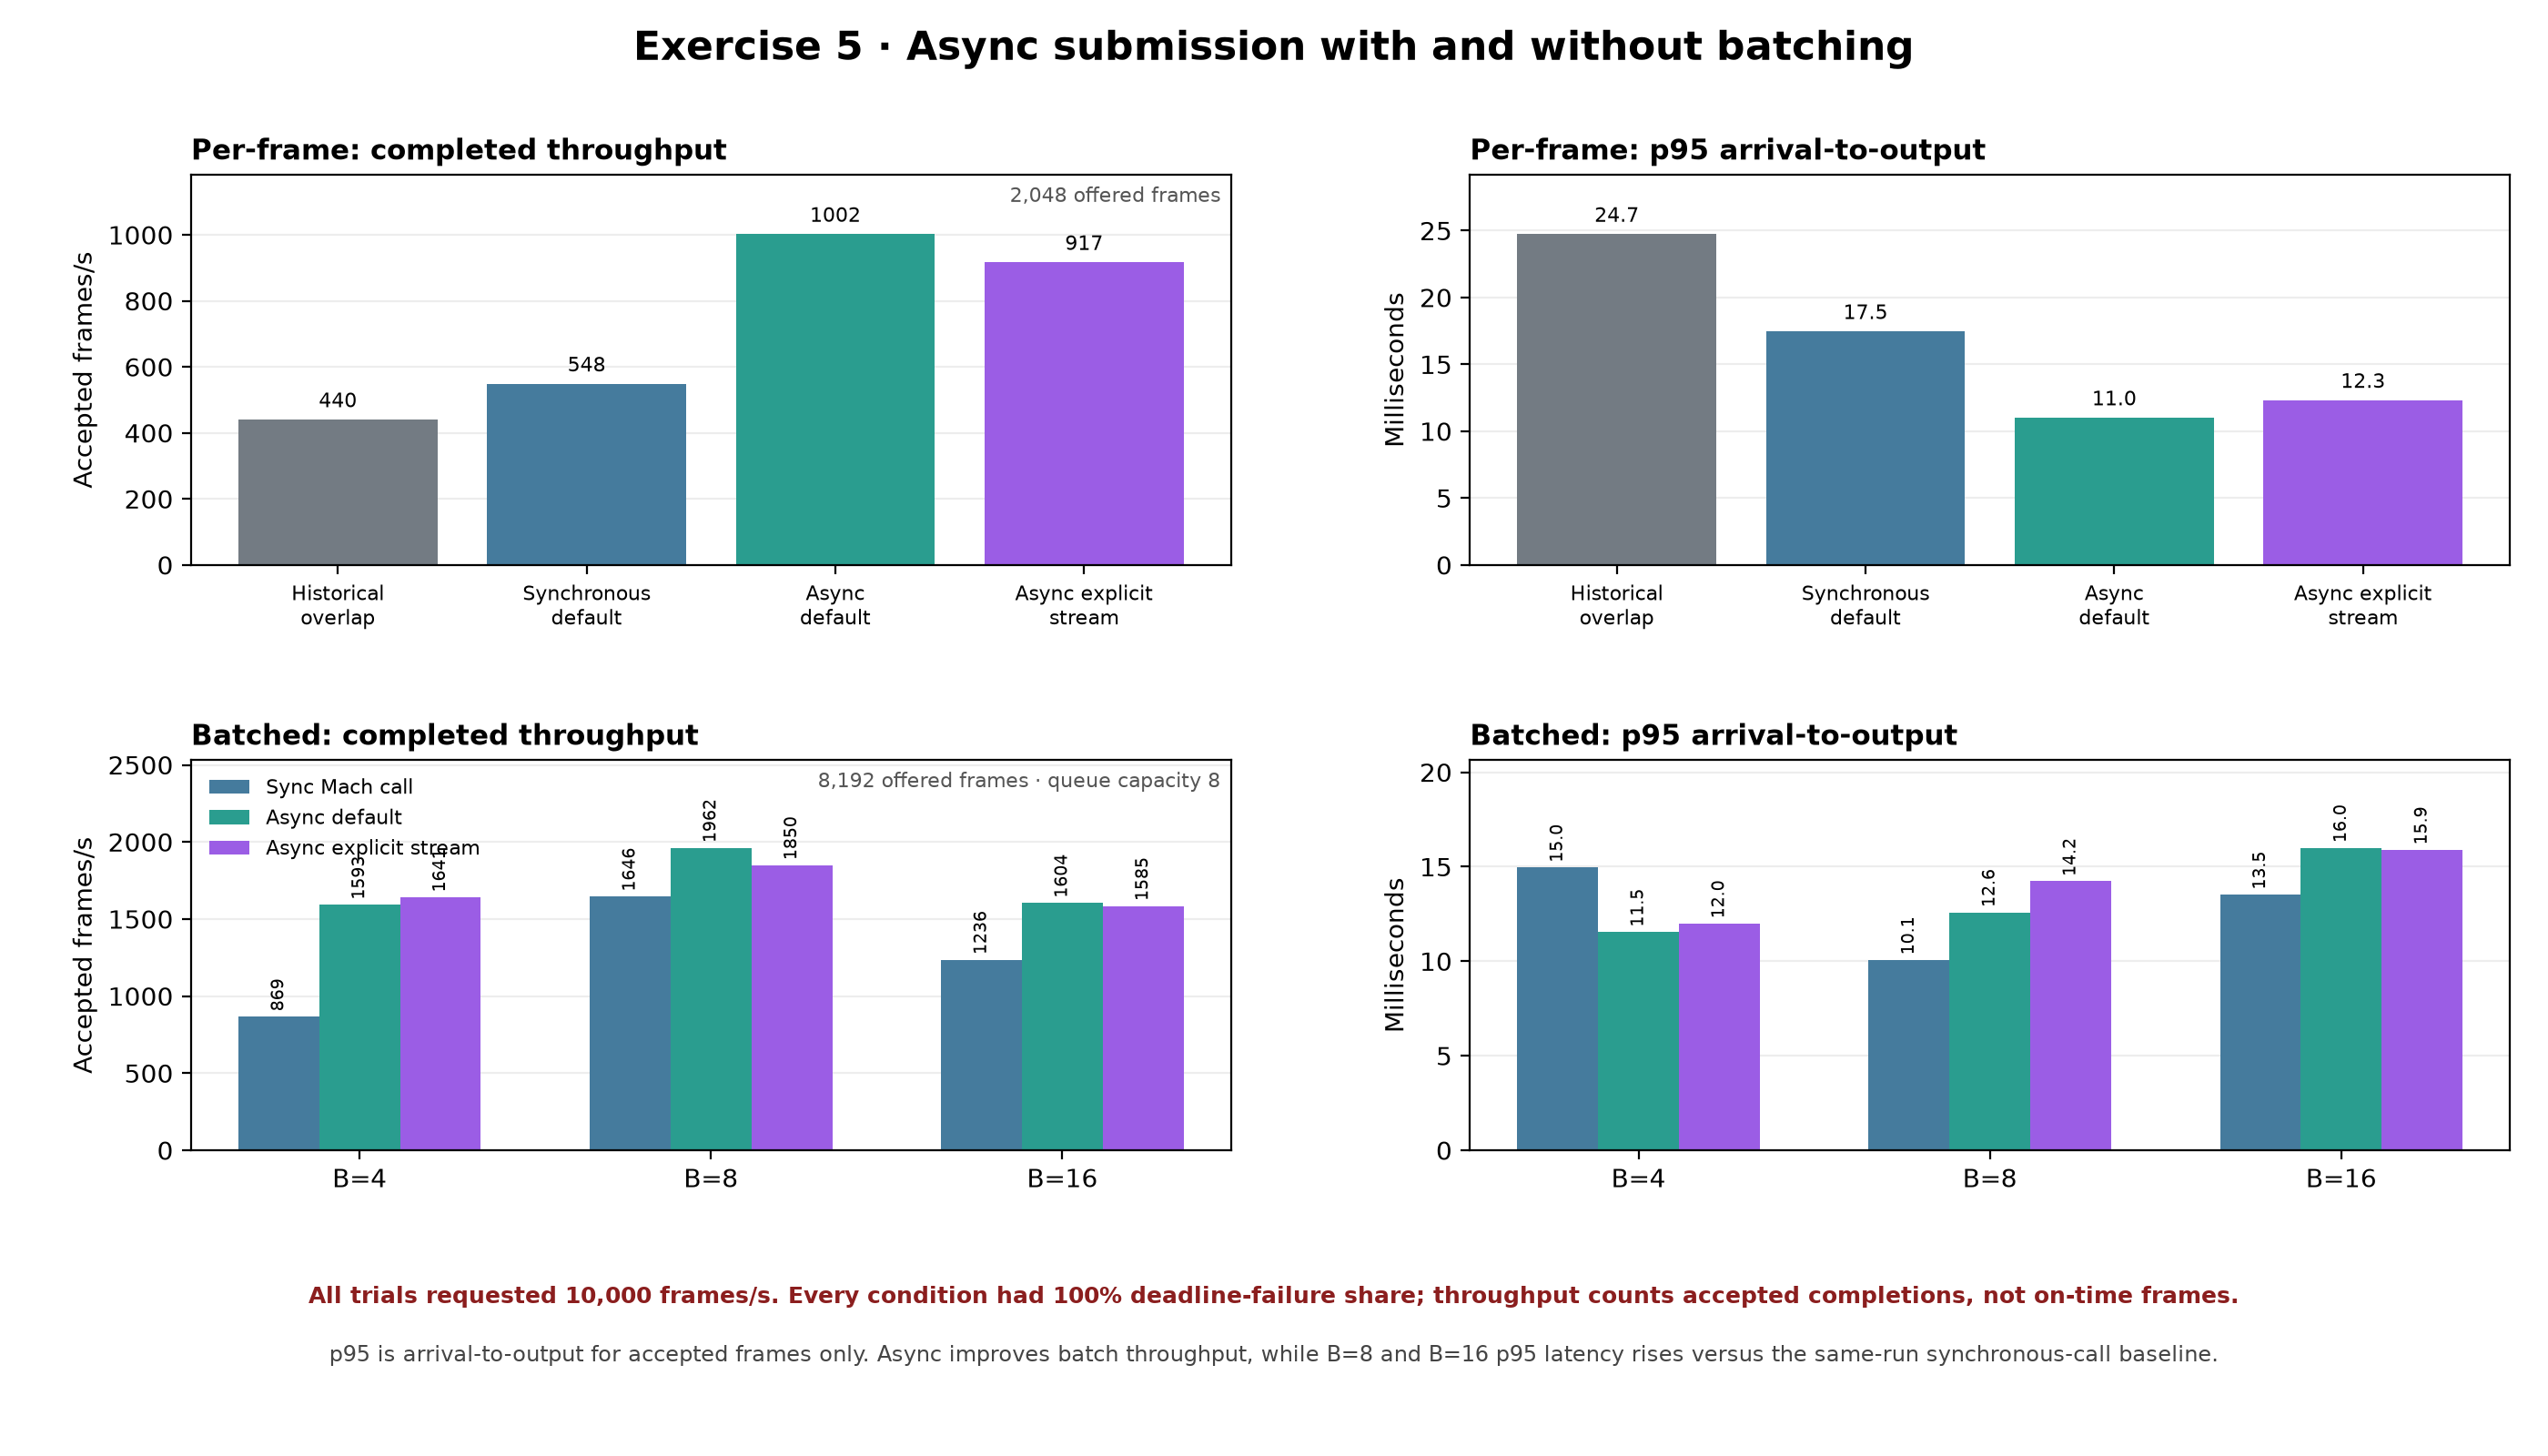

The complete-map checks matched the synchronous result (relative RMSE 0). Every scheduled condition had 100% failure share; the table reports completed accepted acquisitions, not on-time frames.

| Batch | Sync Mach call | Async default | Async explicit | Best async gain vs sync |
|---|---:|---:|---:|---:|
| B=4 | 869/s | 1,593/s | 1,641/s | +88.9% (explicit) |
| B=8 | 1,646/s | 1,962/s | 1,850/s | +19.2% (default) |
| B=16 | 1,236/s | 1,604/s | 1,585/s | +29.8% (default) |

Async raised throughput at each size, but the explicit stream was not consistently faster. `B=8` async default was best at 1,962/s (19.6% of offered rate); p95 output age remained far above every batch deadline. Use the paired synchronous results above as the baseline; earlier batch-only runs are separate trials.

## Exercise 5: experiment summary and findings

| Question | Variables tested | Finding |
|---|---|---|
| How does load affect the scheduled pipeline? | Serialized vs historical two-slot path; 13 rates from 200 Hz to 10 kHz; 8,192 frames | Both paths passed 200 Hz. No frame was on time by 1 kHz. At 10 kHz, all offered frames were dropped or late; GPU work took about 1.5 ms against a 0.1 ms period. |
| Does batching help? | Offline and scheduled `B=1,2,4,8,16`; scheduled `B=32` | Offline `B=16` reached 5,479 acquisitions/s vs 824 at `B=1`, with RMSE ≤`1.18e-7`. Scheduled `B=8` was fastest in the batch-only run (1,463/s), but all frames still failed deadlines. |
| Does queue depth help? | `B=8`, 10 kHz, queue 8 through 8,192 | A full queue preserved the complete map (RMSE `3.70e-6`) but all frames were late and p95 output age reached 4.04 s. Buffering traded drops for stale output. |
| Does Mach async submission help? | Four Mach modes; then historical sync, async default, and async explicit at `B=4,8,16` | At 10 kHz, async default reached 1,002/s vs 548/s for `synchronous_default` in the 2,048-frame prototype; in the paired `B=8` run it reached 1,962/s vs 1,646/s (+19.2%). The 200 Hz full-map checks matched exactly. Every offered frame still dropped or completed late. |
| Can independent beamforms overlap usefully? | `B=8`, one vs two explicit streams, 32 resident inputs | Nsight confirmed brief overlap, but two streams improved median rate by only 0.9% (2,840 vs 2,815/s). No material capacity gain was measured. |
| What did GPU profiling show? | B=8 async-default Nsight Systems/GPU metrics and isolated Nsight Compute; two-stream Nsight trace | The Nsight Systems GPU-metrics capture saw 30 B=8 beamforms (mean 1.82 ms), reductions (0.762 ms), and H2D copies (0.232 ms). Separate isolated Nsight Compute profiles reported B=8 active warps of 42.56% and SM throughput of 39.91%; the earlier B=16 profile reported 84.6% occupancy, 67.4% SM throughput, and 4.1% DRAM throughput. These are per-kernel results from different batch sizes, not total-pipeline or two-stream counters. Instrumented run rates varied, so traces support timeline/counter interpretation, not performance ranking. |

The two improvement directions are distinct: **concurrent compute** tries to use GPU resources left idle by one beamform; **higher utilization** reduces gaps between copies, launches, and compute. The final two-stream test found little benefit from the first. Batching and async submission helped the second, but service remained far below 10 kHz. The traces do not prove the T4 is fully saturated; they show that the tested paths still need substantially shorter service time to meet the 10 kHz deadline. Test lower work per acquisition or a faster GPU next; a larger queue alone only delays the failures.